# Proyek Machine Learning: Prediksi Harga Rumah (House Prices)
**Topik:** Data Cleaning, Preprocessing, Exploratory Data Analysis (EDA), dan Pemodelan Regresi  
**Dataset:** Ames Housing / House Prices Dataset (1.460 baris, 81 fitur)

> **Catatan Proyek:**  
> Di notebook ini, kami mendokumentasikan proses belajar dalam mengolah data mentah dari awal: menangani *missing value* dan *outlier*, melakukan *standardisasi* serta *feature encoding*, hingga melatih dan mengevaluasi 7 model regresi machine learning untuk memprediksi harga jual rumah (`SalePrice`).

## 0. Setup Environment & Library
Di tahap awal ini, kita mengimpor library utama untuk pengolahan data (`pandas`, `numpy`), visualisasi (`matplotlib`, `seaborn`), serta algoritma pemodelan dan evaluasi dari `scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("pandas  :", pd.__version__)
print("numpy   :", np.__version__)
print("seaborn :", sns.__version__)

pandas  : 3.0.2
numpy   : 2.4.4
seaborn : 0.13.2


## 1. Eksplorasi Awal & Informasi Dataset
Langkah pertama kami adalah memuat dataset dan memeriksa struktur dasarnya: jumlah baris, kolom, tipe data, serta nilai yang hilang. Ini penting agar kita tahu strategi preprocessing yang tepat untuk tiap kolom.

### 1.1 Memuat Dataset

In [2]:
train = pd.read_csv("train.csv")

print("Shape dataset :", train.shape)
train.head()

Shape dataset : (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 1.2 Memeriksa Tipe Data
Kita gunakan `train.info()` untuk melihat ringkasan tipe data dan jumlah nilai non-null pada setiap fitur.

In [3]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

**Temuan Awal:**
- Dataset terdiri dari **1.460 baris** dan **81 kolom**.
- Sebagian besar kolom bertipe numerik (`int64`, `float64`), dan sisanya berupa kategorikal (`object`).
- Kolom yang bertipe `float64` umumnya merupakan kolom integer yang mengandung missing value (`NaN`) sehingga otomatis diubah oleh pandas.

In [4]:
kolom_numerik = train.select_dtypes(include=[np.number]).columns
kolom_kategorik = train.select_dtypes(include=["object"]).columns

print("Jumlah kolom numerik     :", len(kolom_numerik))
print("Jumlah kolom kategorikal :", len(kolom_kategorik))
print("Total kolom              :", train.shape[1])

print("\nDaftar kolom kategorikal:")
print(list(kolom_kategorik))

Jumlah kolom numerik     : 38
Jumlah kolom kategorikal : 43
Total kolom              : 81

Daftar kolom kategorikal:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


### 1.3 Analisis Statistik Deskriptif
Di sini kita cek ringkasan statistik (`count`, `mean`, `std`, `min`, `max`, kuartil) untuk melihat sebaran angka pada fitur numerik dan mendeteksi apakah ada rentang nilai yang janggal atau jomplang.

In [5]:
# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460.000000,1460.000000,1460.000000,1460.000000,1460,1460,1460,1460,588,1452.000000,1460,1460,1460,1423,1423,1422,1423,1460.000000,1422,1460.000000,1460.000000,1460.000000,1460,1460,1460,1459,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460,1460.000000,1460,1460.000000,770,1379,1379.000000,1379,1460.000000,1460.000000,1379,1379,1460,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,5,3,25,9,8,5,8,NaN,NaN,NaN,NaN,6,8,15,16,3,NaN,4,5,6,4,4,4,6,NaN,6,NaN,NaN,NaN,6,5,2,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,7,NaN,5,6,NaN,3,NaN,NaN,5,5,3,NaN,NaN,NaN,NaN,NaN,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,NaN,NaN,NaN,NaN,Gable,CompShg,VinylSd,VinylSd,BrkFace,NaN,TA,TA,PConc,TA,TA,No,Unf,NaN,Unf,NaN,NaN,NaN,GasA,Ex,Y,SBrkr,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TA,NaN,Typ,NaN,Gd,Attchd,NaN,Unf,NaN,NaN,TA,TA,Y,NaN,NaN,NaN,NaN,NaN,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,1052,1382,225,1260,1445,1220,726,NaN,NaN,NaN,NaN,1141,1434,515,504,445,NaN,906,1282,647,649,1311,953,430,NaN,1256,NaN,NaN,NaN,1428,741,1365,1334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,735,NaN,1360,NaN,380,870,NaN,605,NaN,NaN,1311,1326,1340,NaN,NaN,NaN,NaN,NaN,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.099315,5.575342,1971.267808,1984.865753,NaN,NaN,NaN,NaN,NaN,103.685262,NaN,NaN,NaN,NaN,NaN,NaN,NaN,443.639726,NaN,46.549315,567.240411,1057.429452,NaN,NaN,NaN,NaN,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,NaN,6.517808,NaN,0.613014,NaN,NaN,1978.506164,NaN,1.767123,472.980137,NaN,NaN,NaN,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.382997,1.112799,30.202904,20.645407,NaN,NaN,NaN,NaN,NaN,181.066207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,456.098091,NaN,161.319273,441.866955,438.705324,NaN,NaN,NaN,NaN,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,NaN,1.625393,NaN,0.644666,NaN,NaN,24.689725,NaN,0.747315,213.804841,NaN,NaN,NaN,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,1872.000000,1950.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,2.000000,NaN,0.000000,NaN,NaN,1900.000000,N

### 1.4 Memeriksa Missing Value
Kita hitung jumlah nilai kosong (`NaN`) di setiap kolom untuk menentukan strategi penanganannya: kolom mana yang cukup diimputasi dan mana yang sebaiknya di-drop karena terlalu banyak data yang hilang.

In [6]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

Kita rangkum daftar kolom yang memiliki missing value beserta persentasenya agar lebih mudah dianalisis.

In [7]:
ringkasan_missing = pd.DataFrame({
    "jumlah_missing": train.isnull().sum(),
    "persen": (train.isnull().sum() / len(train) * 100).round(2),
})
ringkasan_missing = ringkasan_missing[ringkasan_missing["jumlah_missing"] > 0]
ringkasan_missing = ringkasan_missing.sort_values("jumlah_missing", ascending=False)

print("Jumlah kolom yang memiliki missing value :", len(ringkasan_missing))
print("Total sel yang kosong                    :", int(train.isnull().sum().sum()))
print()
ringkasan_missing

Jumlah kolom yang memiliki missing value : 19
Total sel yang kosong                    : 7829



,jumlah_missing,persen
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


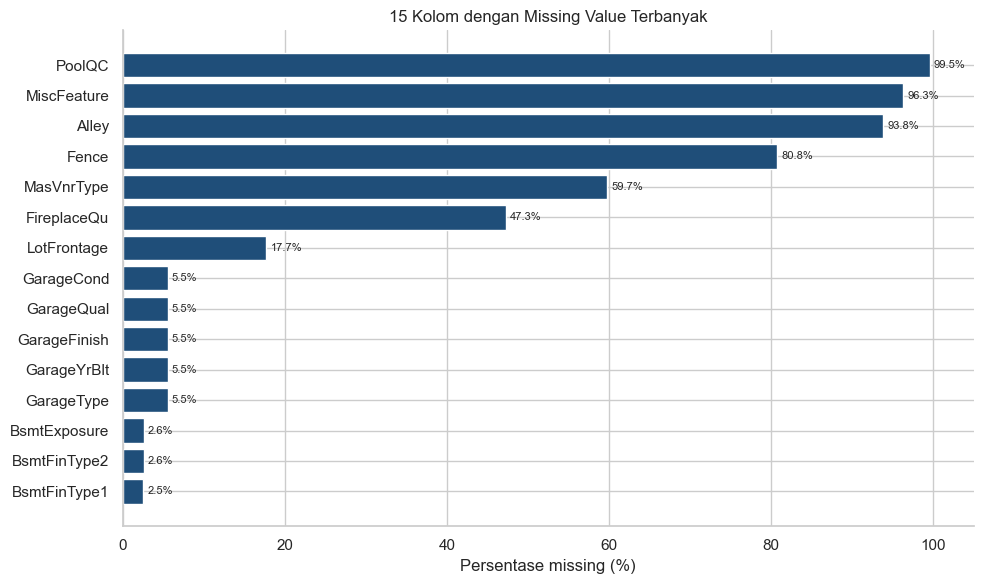

In [8]:
# Visualisasi kolom dengan missing value terbanyak
top_missing = ringkasan_missing.head(15).sort_values("jumlah_missing")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top_missing.index, top_missing["persen"], color="#1f4e79")
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in top_missing["persen"]], padding=3, fontsize=8)
ax.set_xlabel("Persentase missing (%)")
ax.set_title("15 Kolom dengan Missing Value Terbanyak")
ax.set_xlim(0, 105)
sns.despine()
plt.tight_layout()
plt.show()

## 2. Penanganan Missing Value
Dari pemeriksaan awal, terdapat sejumlah fitur dengan data kosong. Strategi yang kami ambil:
1. **Missing > 75% (atau > 1.000 baris):** Dihapus (*drop*) karena informasinya terlalu sedikit dan berisiko bias jika diimputasi.
2. **Missing < 75%:** Diisi nilainya (*imputasi*) sesuai karakteristik data.

In [9]:
# Memisahkan kolom berdasarkan jumlah missing value
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

print("Kolom dengan missing < 1000 (akan diimputasi):", len(less))
print("Kolom dengan missing >= 1000 (akan dihapus)  :", len(over))
print()
print("Daftar kolom 'over' :", list(over))

Kolom dengan missing < 1000 (akan diimputasi): 77
Kolom dengan missing >= 1000 (akan dihapus)  : 4

Daftar kolom 'over' : ['Alley', 'PoolQC', 'Fence', 'MiscFeature']


### 2.1 Imputasi Kolom Numerik (Median)
Untuk fitur numerik dengan missing value < 75%, kita isi menggunakan **median** kolom masing-masing karena median lebih kebal terhadap nilai ekstrem (outlier) dibanding mean.

In [10]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=["number"]).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

*Catatan langkah:* Baris pertama menyaring fitur numerik ber-missing value rendah, lalu baris kedua mengisi `NaN` dengan nilai mediannya.

In [11]:
print("Kolom numerik yang diimputasi :", len(numeric_features))
print(list(numeric_features))

Kolom numerik yang diimputasi : 38
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']


### 2.2 Imputasi Kolom Kategorikal (Modus)
Untuk fitur kategorikal/string, kita tidak bisa memakai median/mean. Solusinya, kita isi dengan **modus** (nilai yang paling sering muncul di kolom tersebut).

In [12]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=["object"]).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

Kita lakukan iterasi pada tiap kolom kategorikal dan mengisi `NaN` dengan nilai modus masing-masing.

In [13]:
print("Kolom kategorikal yang diimputasi :", len(kategorical_features))
print()
pd.DataFrame({
    "modus_pengisi": [train[c].mode()[0] for c in kategorical_features],
}, index=list(kategorical_features))

Kolom kategorikal yang diimputasi : 39



,modus_pengisi
MSZoning,RL
Street,Pave
LotShape,Reg
LandContour,Lvl
Utilities,AllPub
LotConfig,Inside
LandSlope,Gtl
Neighborhood,NAmes
Condition1,Norm
Condition2,Norm


### 2.3 Menghapus Kolom dengan Missing Value Tinggi (>75%)
Kolom dengan missing value di atas 75% (seperti `Alley`, `PoolQC`, `Fence`, `MiscFeature`) kita hapus karena datanya hampir kosong sehingga kurang bermanfaat untuk pemodelan.

In [14]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

print("Shape sebelum drop :", train.shape)
print("Shape sesudah drop :", df.shape)
print("Kolom yang dihapus  :", list(over))

Shape sebelum drop : (1460, 81)
Shape sesudah drop : (1460, 77)
Kolom yang dihapus  : ['Alley', 'PoolQC', 'Fence', 'MiscFeature']


*Catatan:* Hasil data yang sudah dibersihkan dari missing value disimpan ke variabel baru `train_clean` agar data mentah aslinya tetap aman dan terlacak.

In [15]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [16]:
print("Total missing value pada df :", int(df.isnull().sum().sum()))
print("Shape df                    :", df.shape)

Total missing value pada df : 0
Shape df                    : (1460, 77)


## 3. Penanganan Outlier (Metode IQR)
Outlier adalah nilai ekstrem yang jauh dari sebaran umum. Keberadaannya dapat membuat model regresi bias, sehingga perlu kita deteksi dan bersihkan.

### 3.1 Visualisasi Outlier dengan Boxplot
Kita gunakan boxplot untuk melihat sebaran titik-titik data yang berada di luar batas kuartil pada tiap fitur numerik.

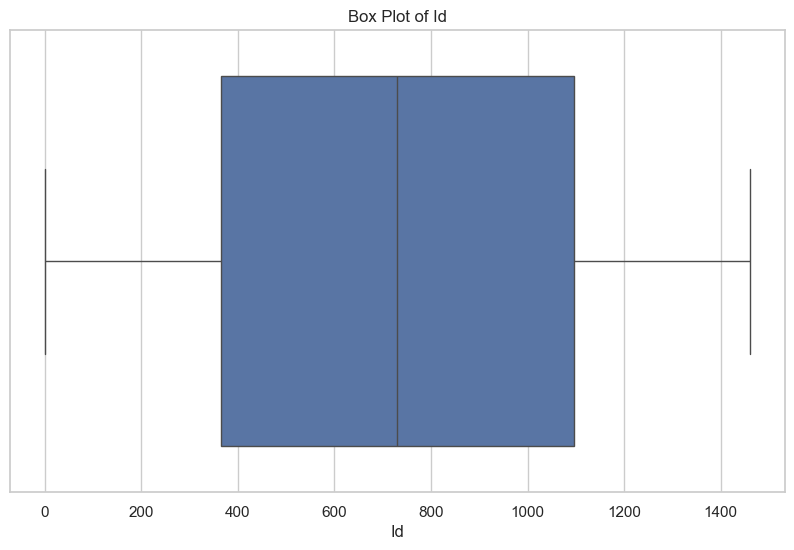

<Figure size 1000x500 with 0 Axes>

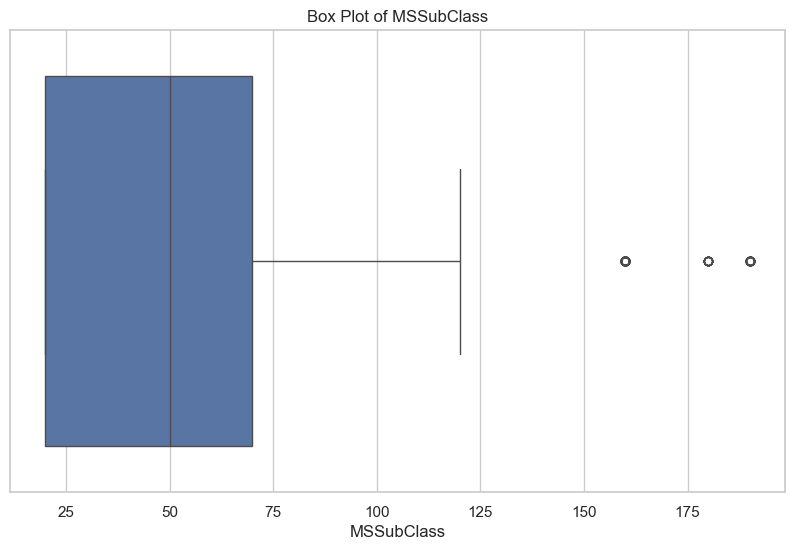

<Figure size 1000x500 with 0 Axes>

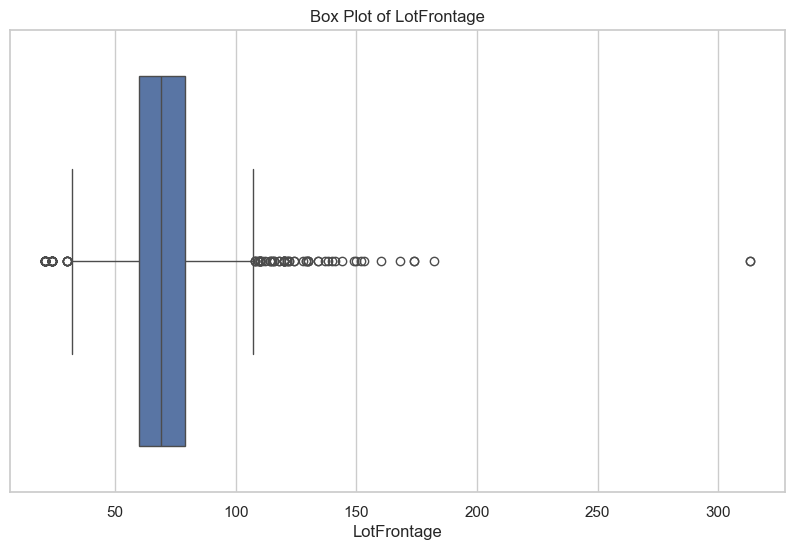

<Figure size 1000x500 with 0 Axes>

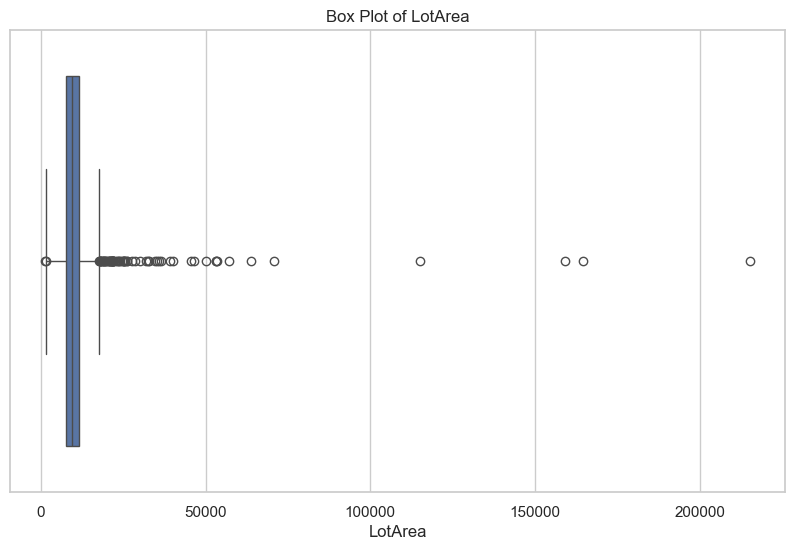

<Figure size 1000x500 with 0 Axes>

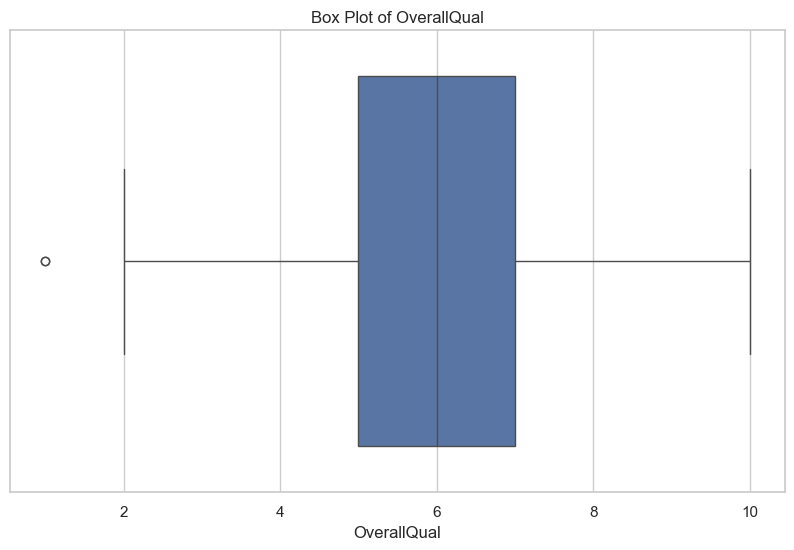

<Figure size 1000x500 with 0 Axes>

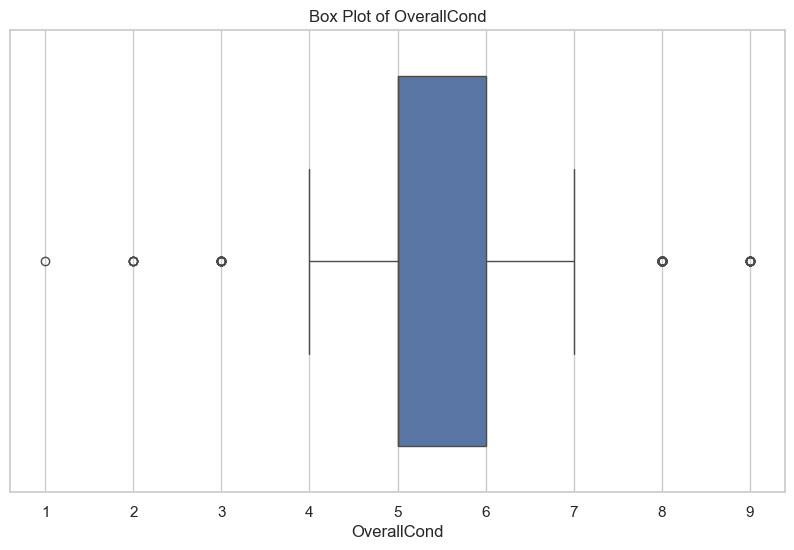

<Figure size 1000x500 with 0 Axes>

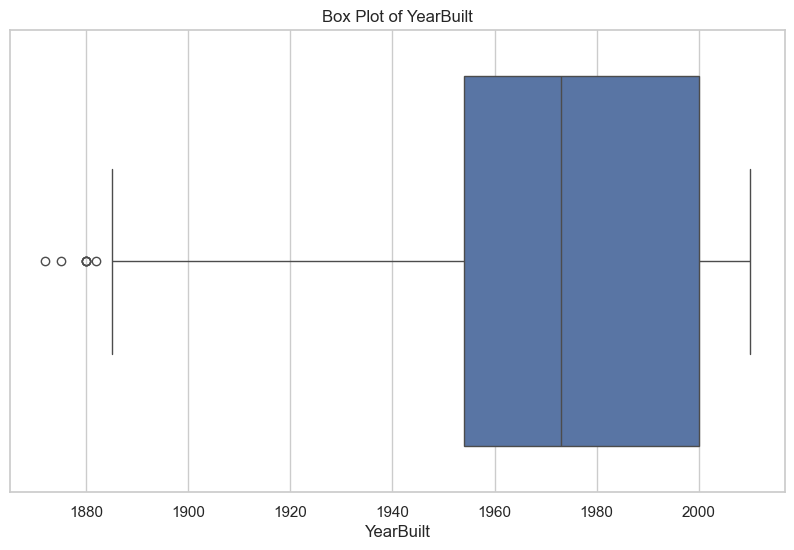

<Figure size 1000x500 with 0 Axes>

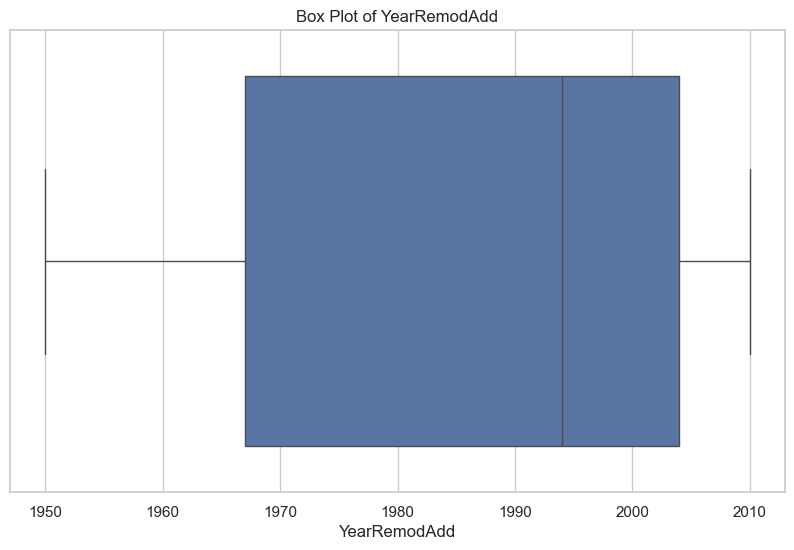

<Figure size 1000x500 with 0 Axes>

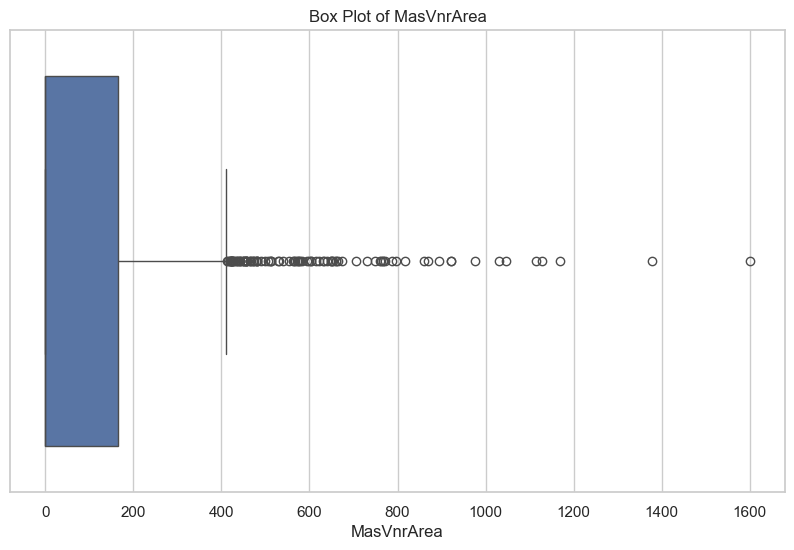

<Figure size 1000x500 with 0 Axes>

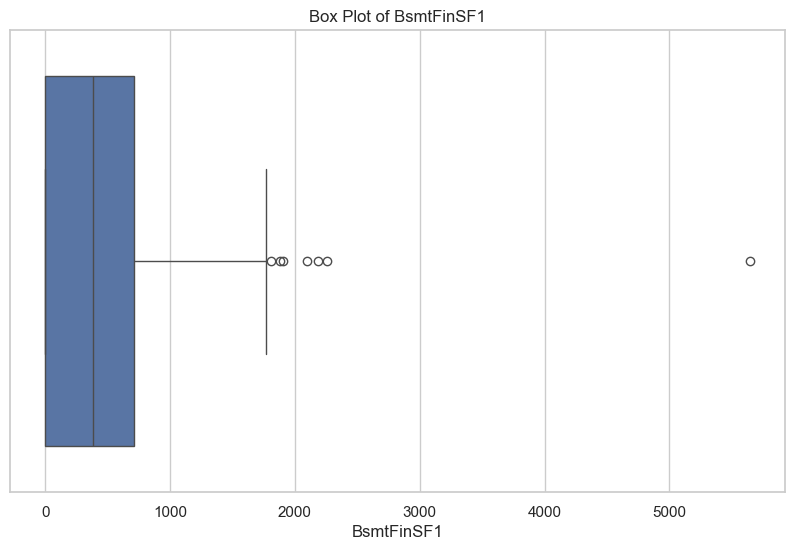

<Figure size 1000x500 with 0 Axes>

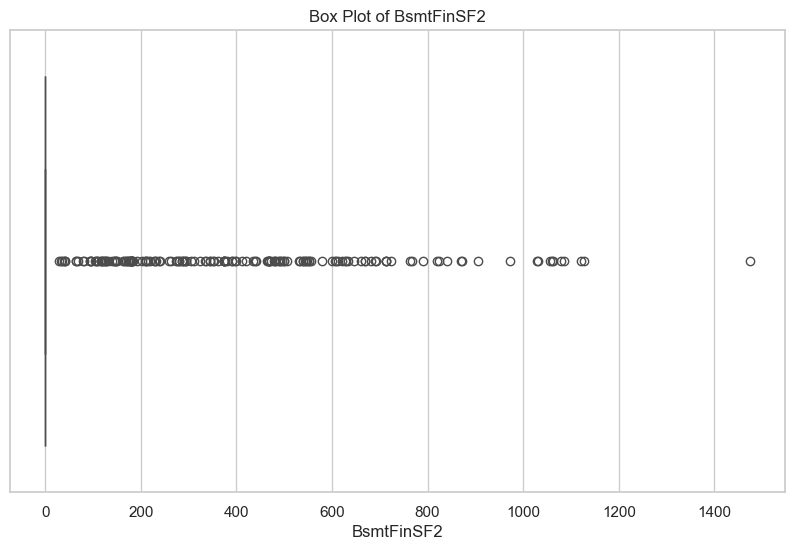

<Figure size 1000x500 with 0 Axes>

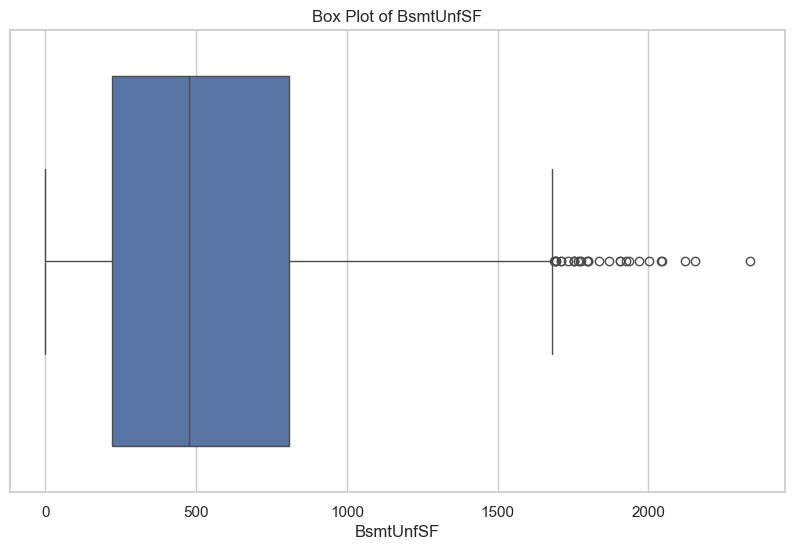

<Figure size 1000x500 with 0 Axes>

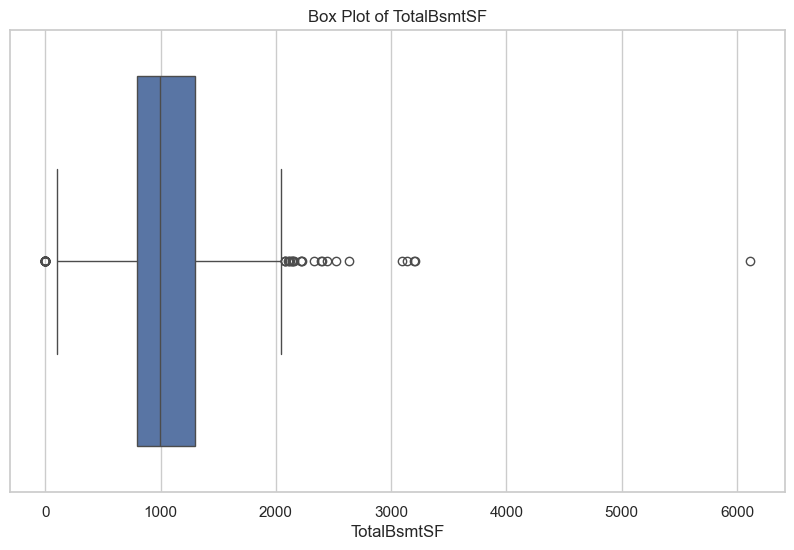

<Figure size 1000x500 with 0 Axes>

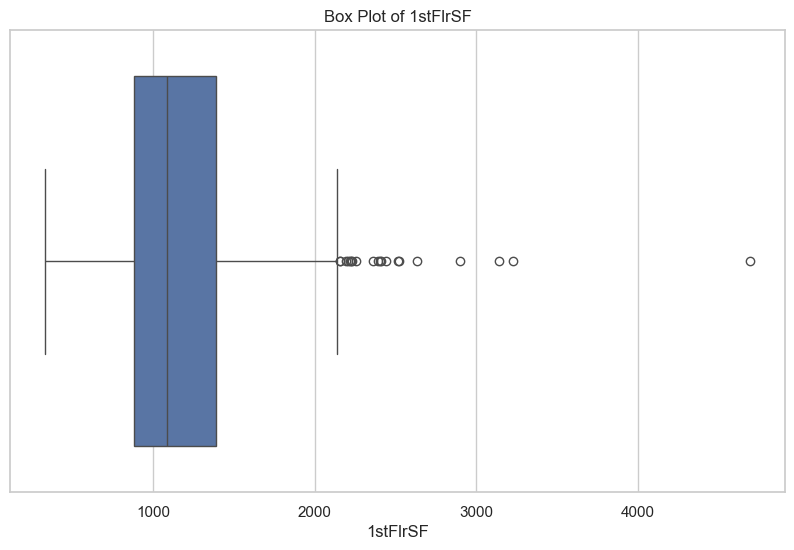

<Figure size 1000x500 with 0 Axes>

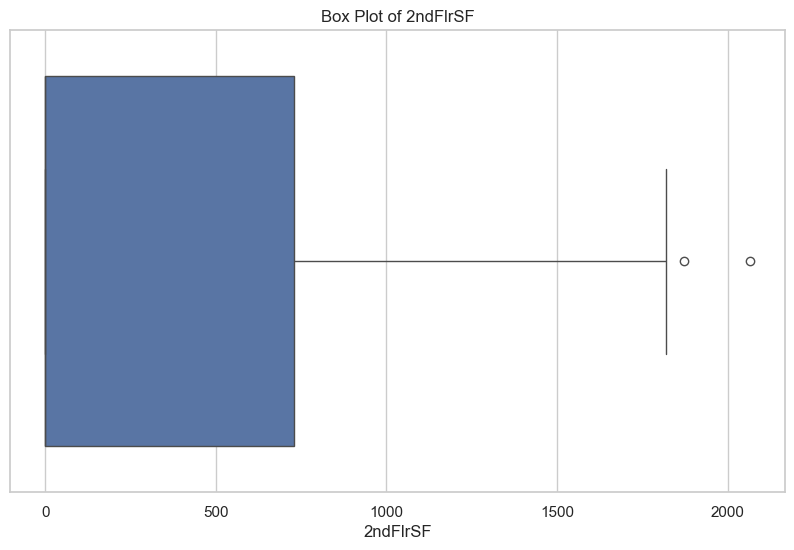

<Figure size 1000x500 with 0 Axes>

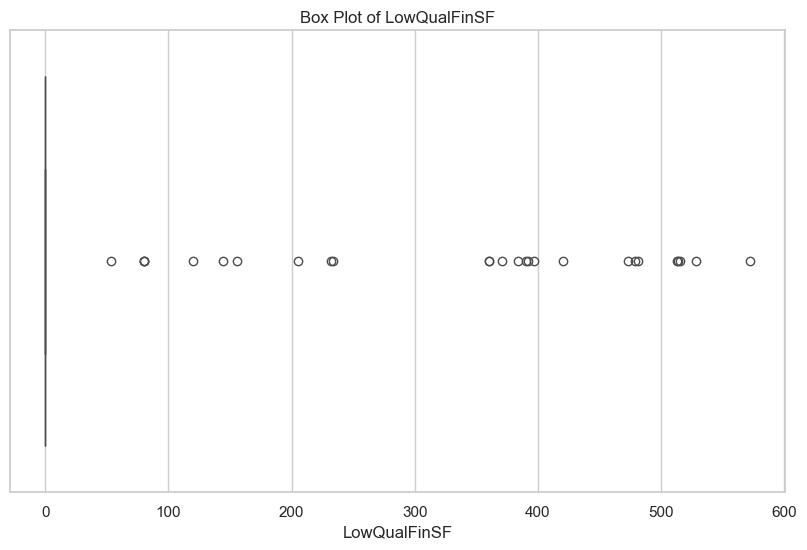

<Figure size 1000x500 with 0 Axes>

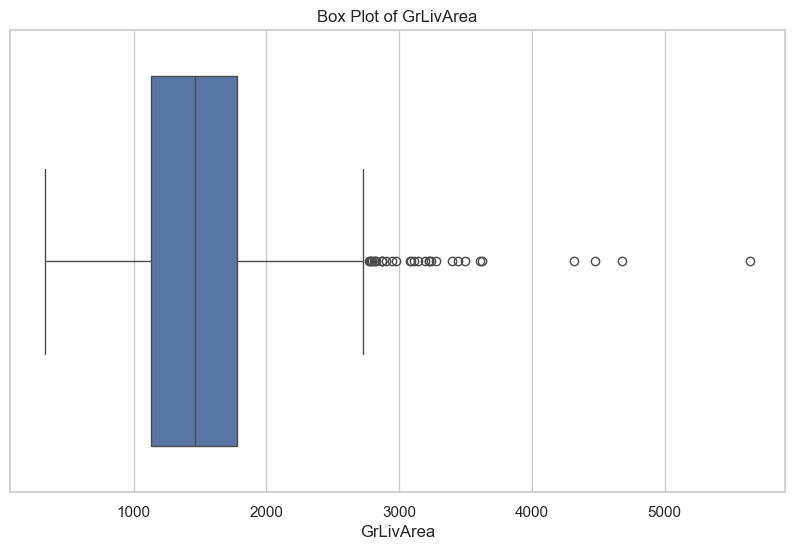

<Figure size 1000x500 with 0 Axes>

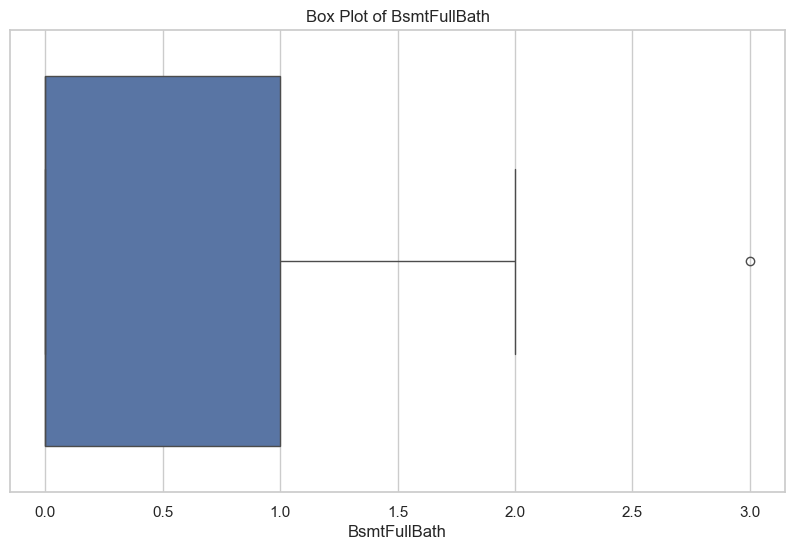

<Figure size 1000x500 with 0 Axes>

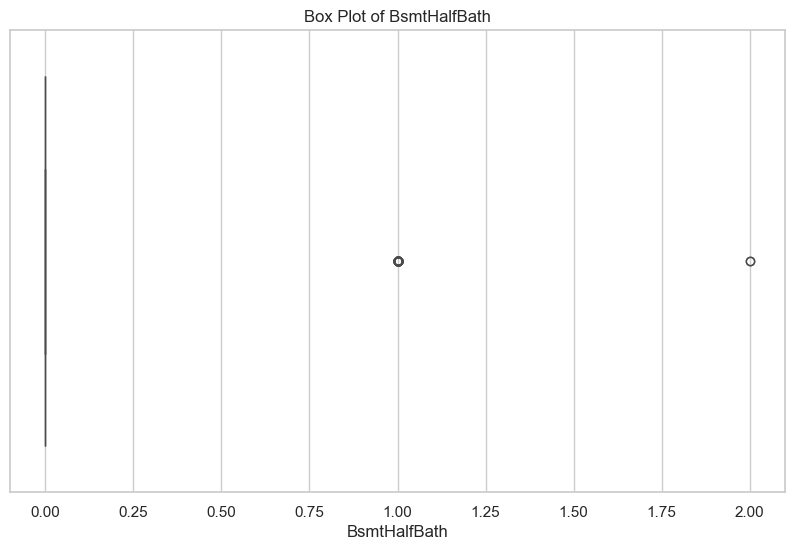

<Figure size 1000x500 with 0 Axes>

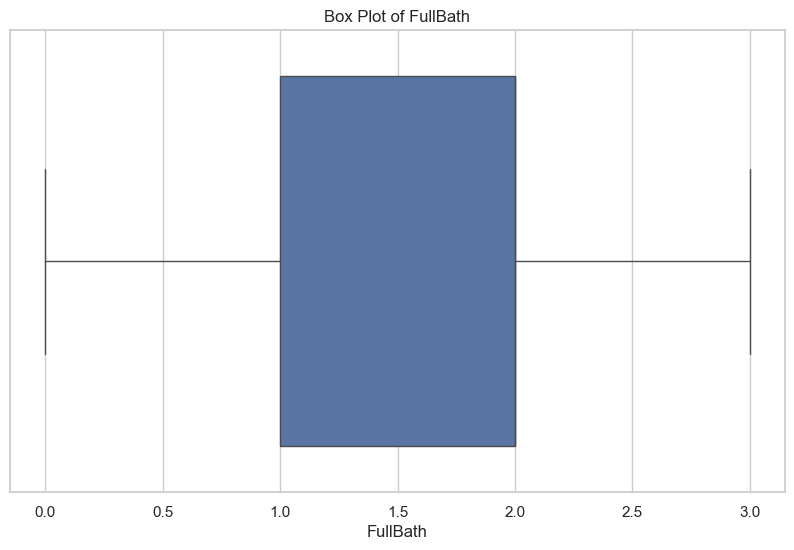

<Figure size 1000x500 with 0 Axes>

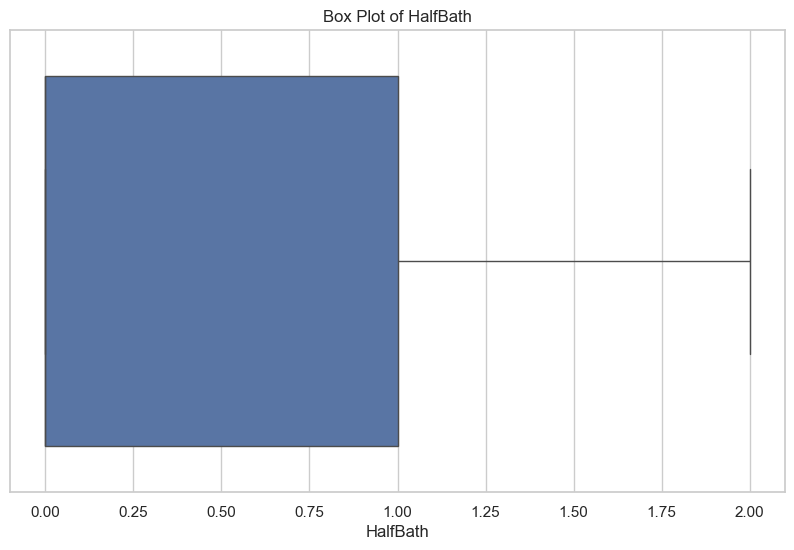

<Figure size 1000x500 with 0 Axes>

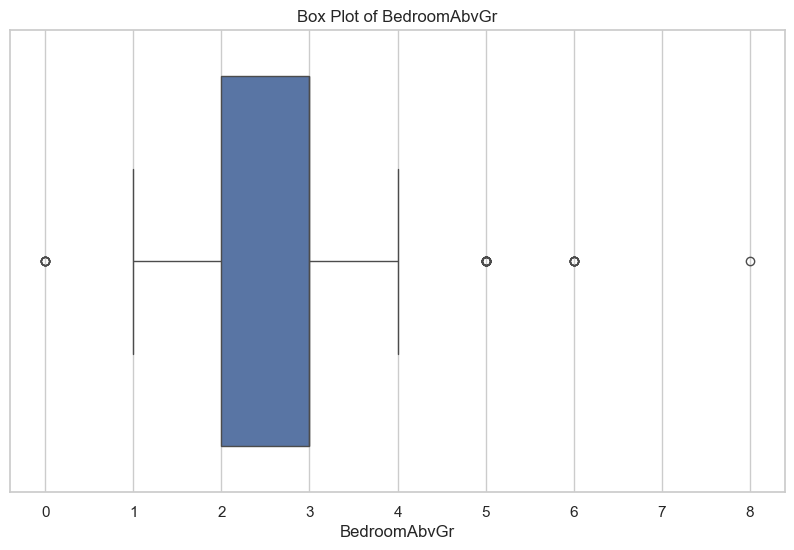

<Figure size 1000x500 with 0 Axes>

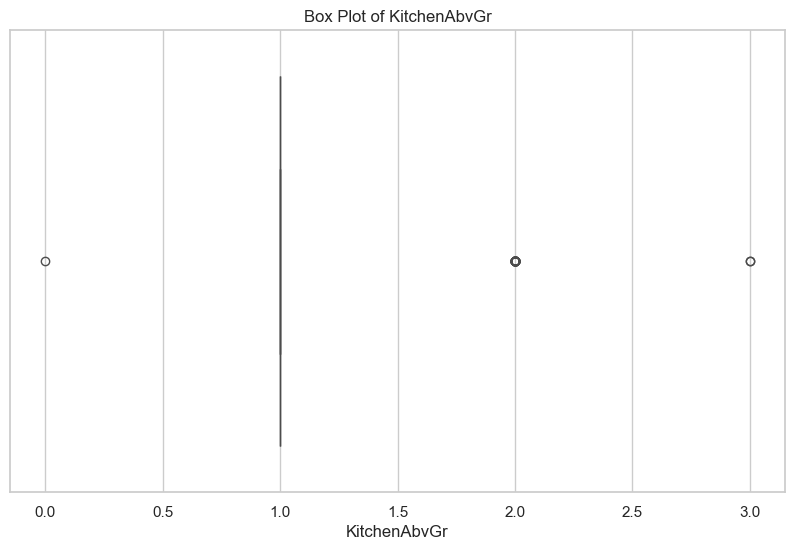

<Figure size 1000x500 with 0 Axes>

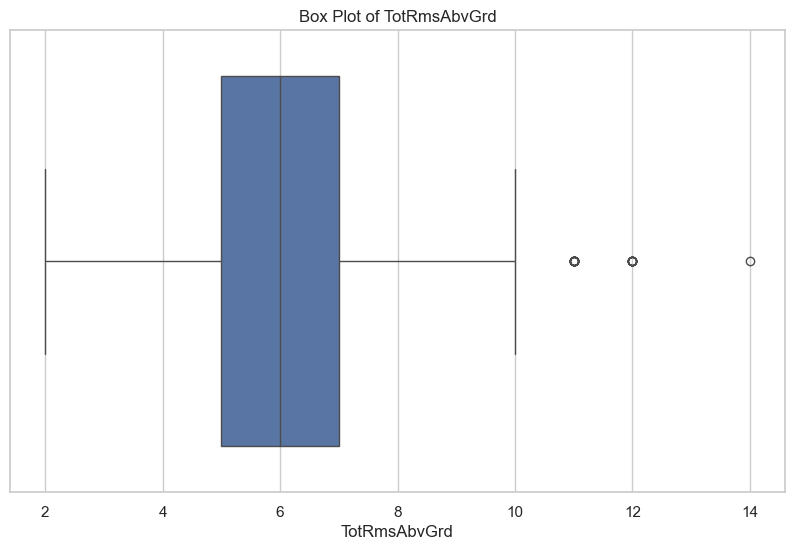

<Figure size 1000x500 with 0 Axes>

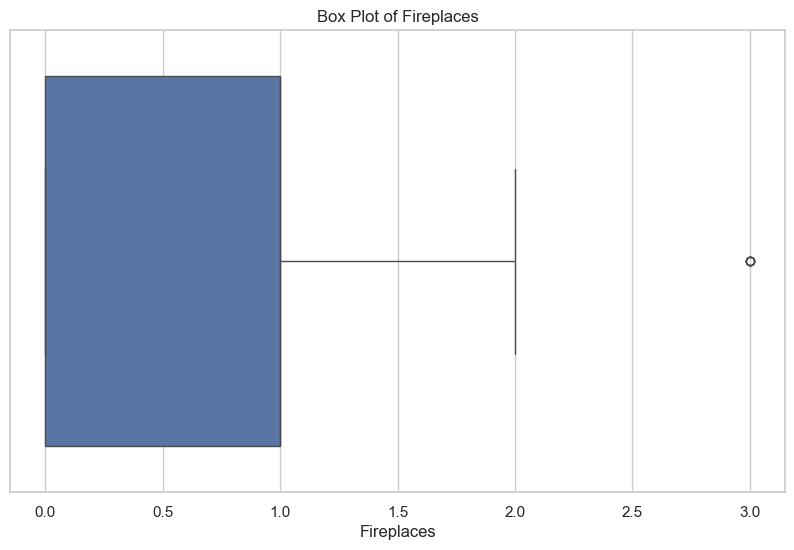

<Figure size 1000x500 with 0 Axes>

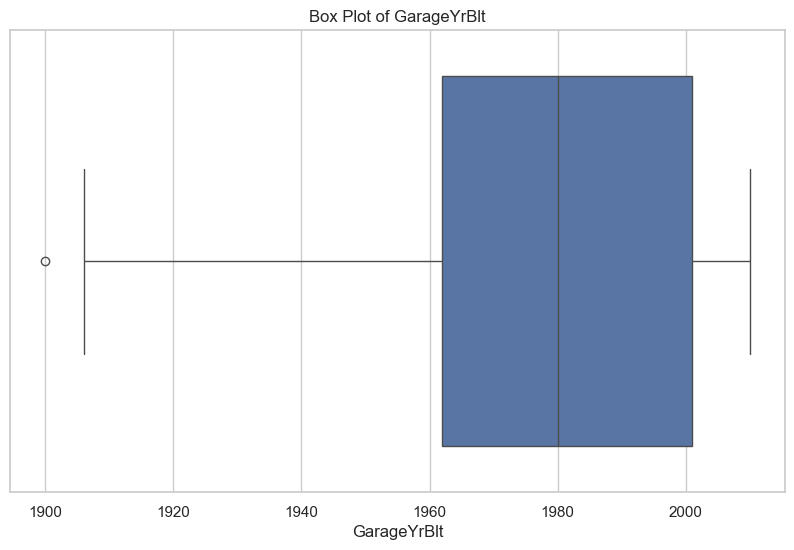

<Figure size 1000x500 with 0 Axes>

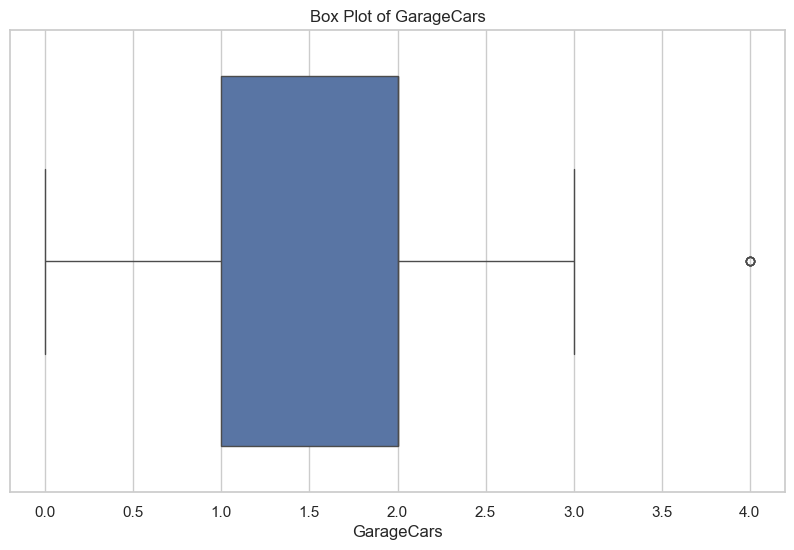

<Figure size 1000x500 with 0 Axes>

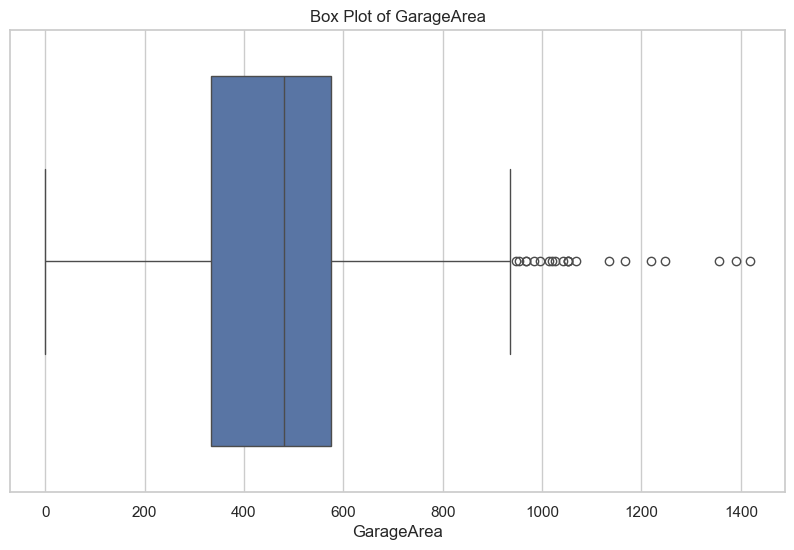

<Figure size 1000x500 with 0 Axes>

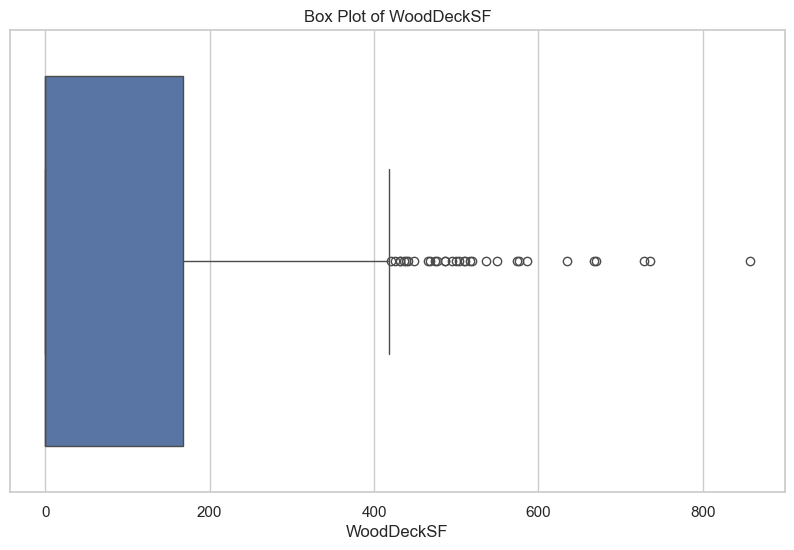

<Figure size 1000x500 with 0 Axes>

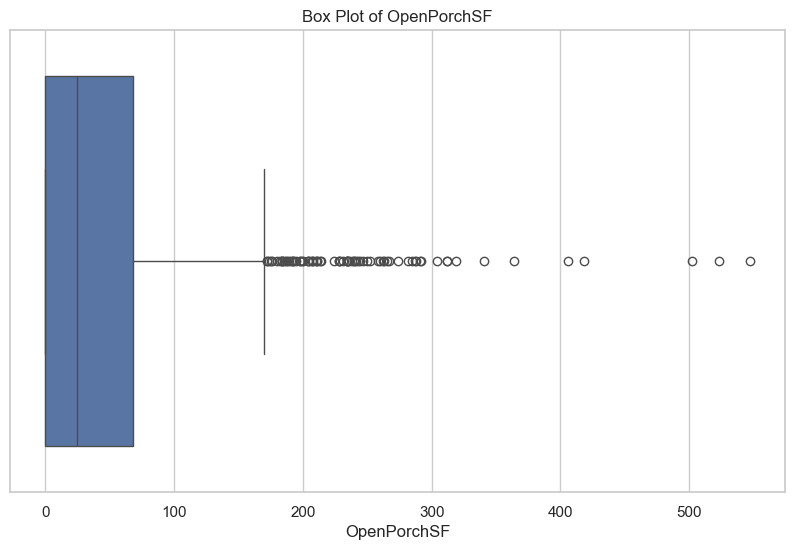

<Figure size 1000x500 with 0 Axes>

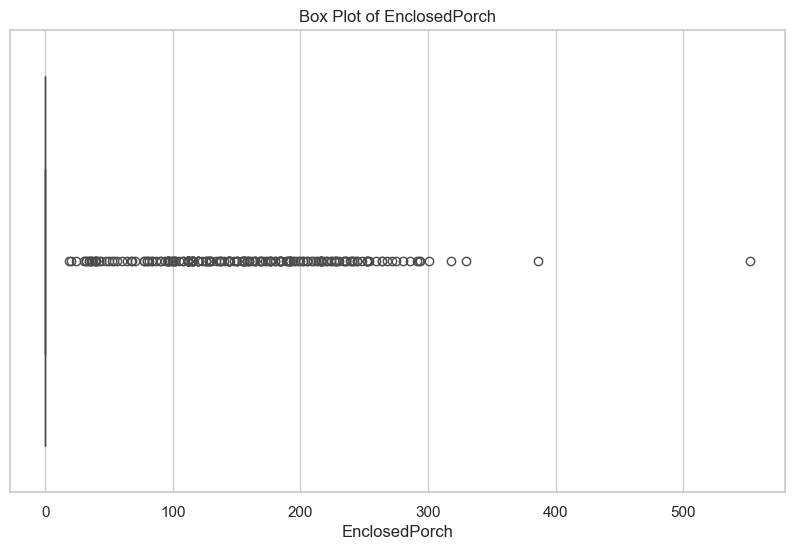

<Figure size 1000x500 with 0 Axes>

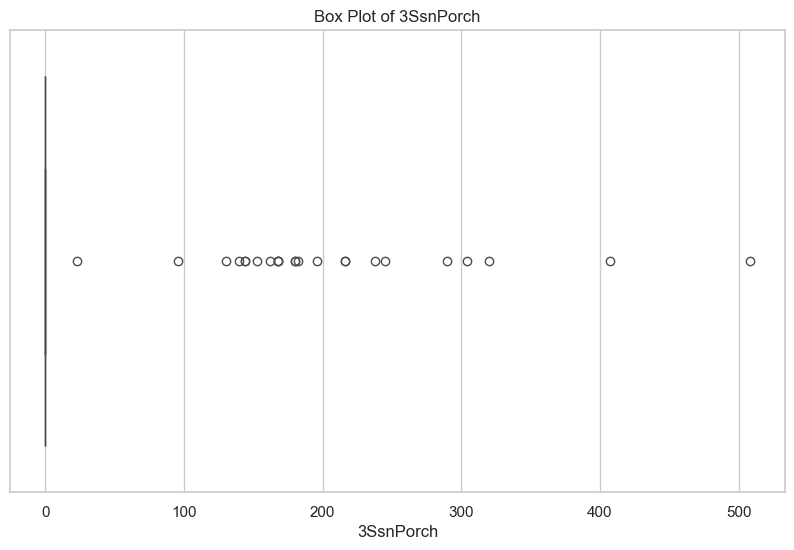

<Figure size 1000x500 with 0 Axes>

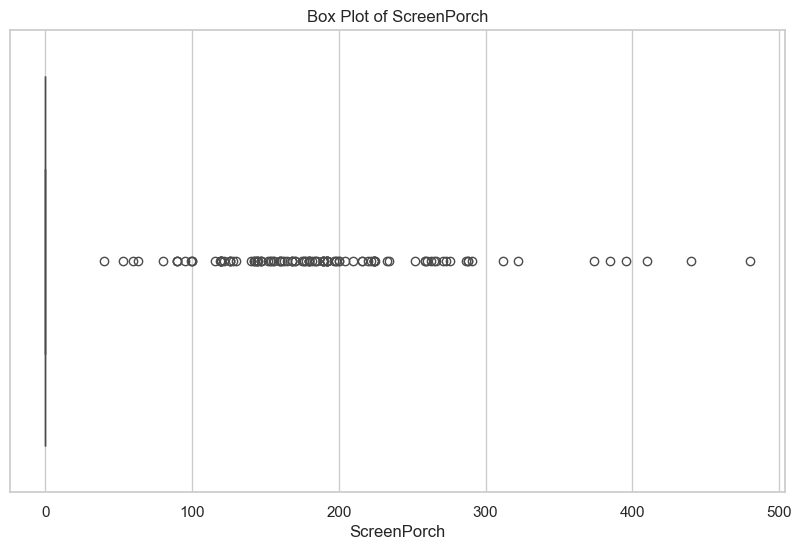

<Figure size 1000x500 with 0 Axes>

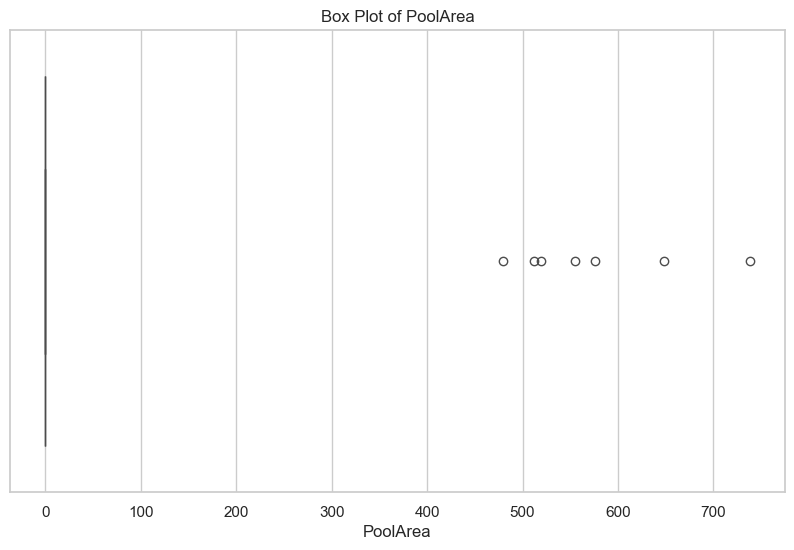

<Figure size 1000x500 with 0 Axes>

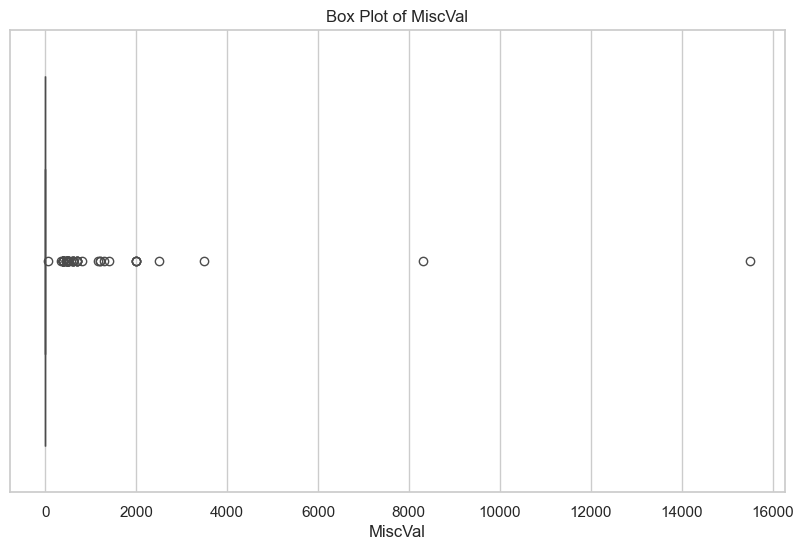

<Figure size 1000x500 with 0 Axes>

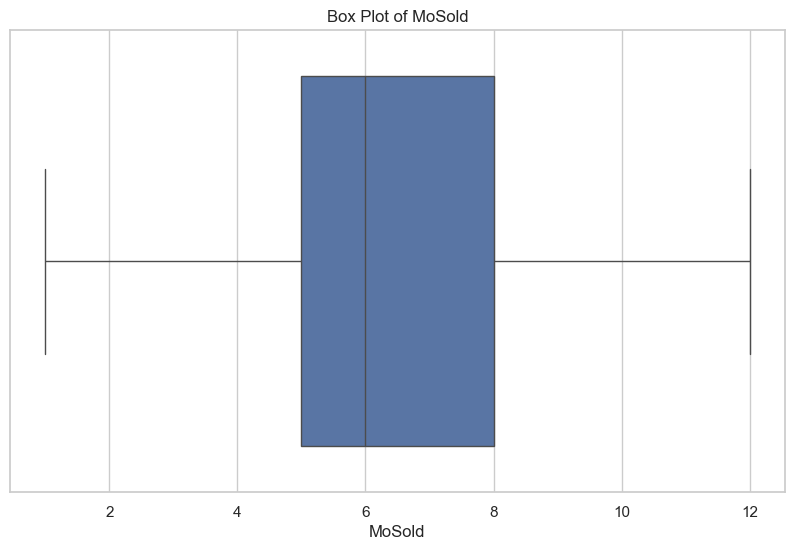

<Figure size 1000x500 with 0 Axes>

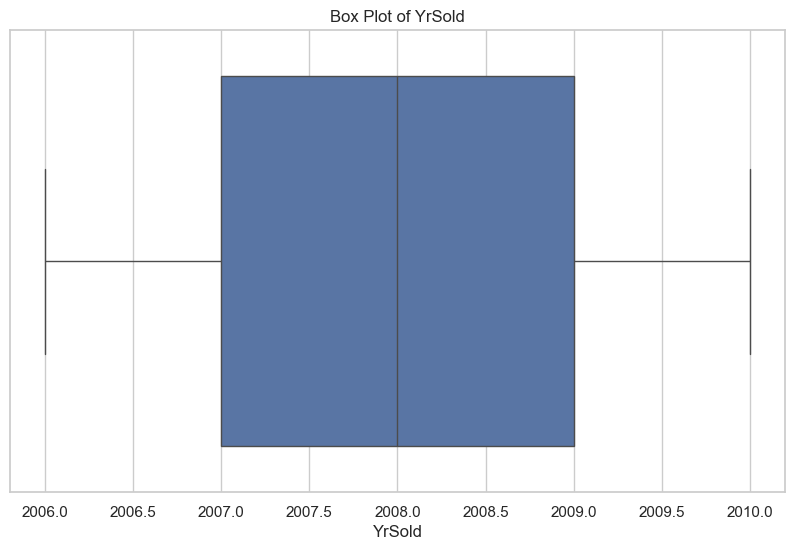

<Figure size 1000x500 with 0 Axes>

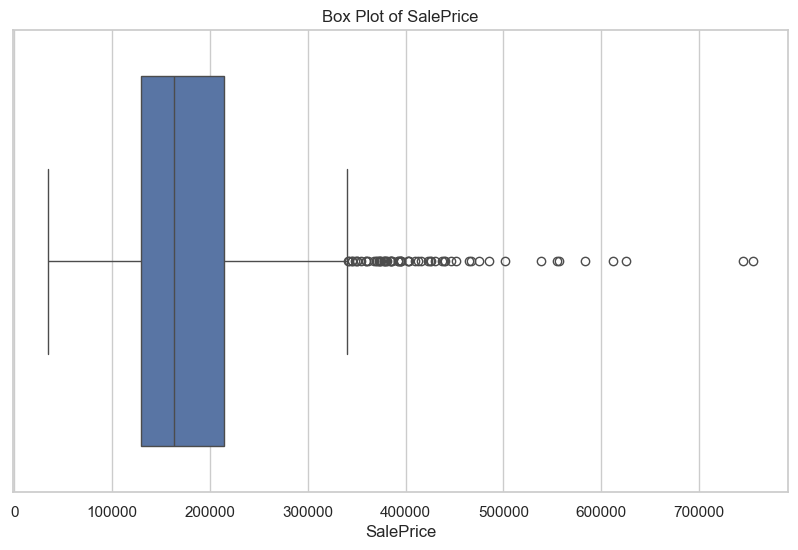

<Figure size 1000x500 with 0 Axes>

In [17]:
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f"Box Plot of {feature}")
    plt.show()
    plt.tight_layout()

> **Cara Baca Boxplot:** Titik-titik di luar garis "kumis" (*whisker*) menunjukkan keberadaan nilai ekstrem (outlier) yang melampaui batas $1.5 	imes \text{IQR}$.

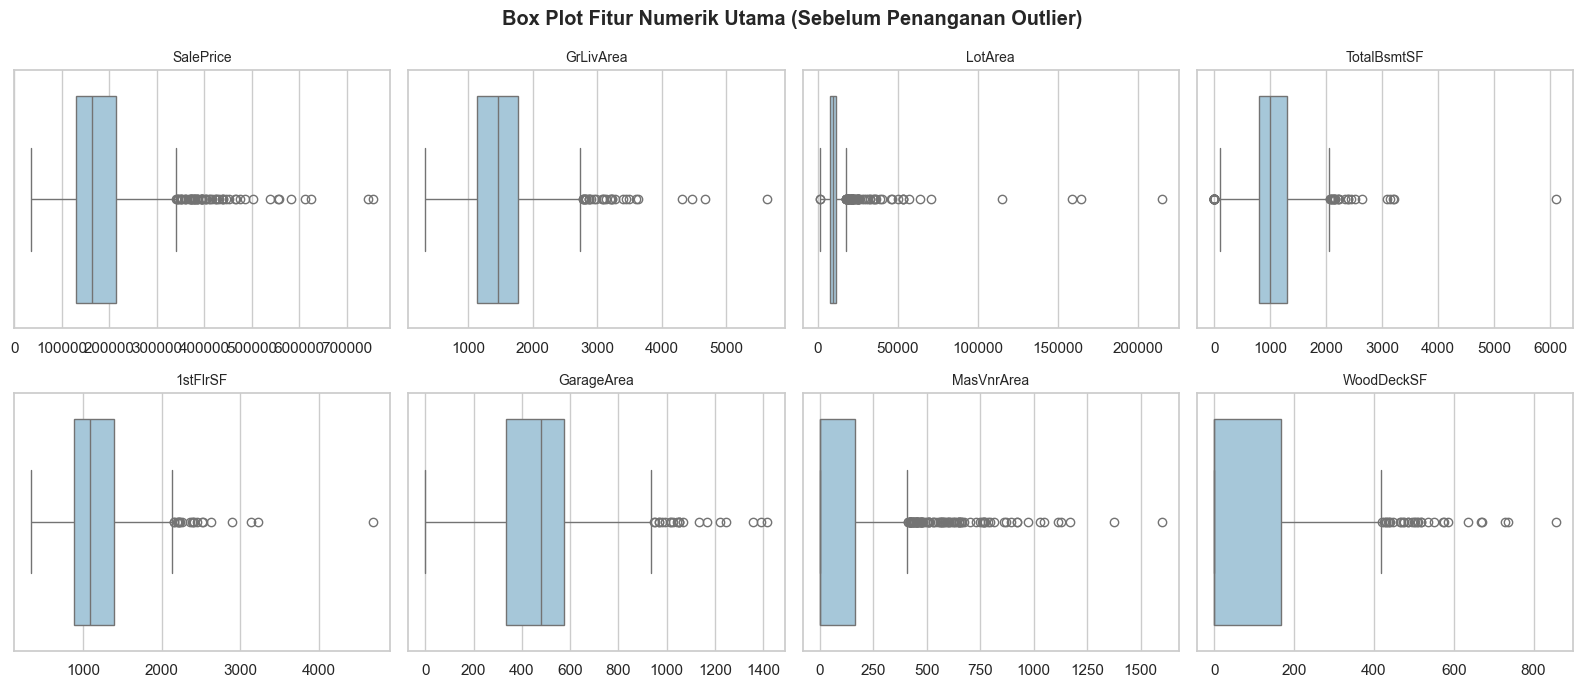

In [18]:
# Boxplot untuk beberapa fitur numerik utama
fitur_utama = ["SalePrice", "GrLivArea", "LotArea", "TotalBsmtSF",
               "1stFlrSF", "GarageArea", "MasVnrArea", "WoodDeckSF"]
fitur_utama = [f for f in fitur_utama if f in df.columns]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, kol in zip(axes.ravel(), fitur_utama):
    sns.boxplot(x=df[kol], ax=ax, color="#9ecae1")
    ax.set_title(kol, fontsize=10)
    ax.set_xlabel("")
plt.suptitle("Box Plot Fitur Numerik Utama (Sebelum Penanganan Outlier)", fontweight="bold")
plt.tight_layout()
plt.show()

### 3.2 Menghitung IQR, Q1, dan Q3
Rumus Interquartile Range (IQR) yang kita gunakan:
$$\text{IQR} = Q3 - Q1$$
- **Batas Bawah:** $Q1 - 1.5 \times \text{IQR}$
- **Batas Atas:** $Q3 + 1.5 \times \text{IQR}$

Data di luar rentang batas tersebut diidentifikasi sebagai outlier.

In [19]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "batas_bawah": Q1 - 1.5 * IQR,
    "batas_atas": Q3 + 1.5 * IQR,
}).round(2)

,Q1,Q3,IQR,batas_bawah,batas_atas
Id,365.75,1095.25,729.50,-728.50,2189.50
MSSubClass,20.00,70.00,50.00,-55.00,145.00
LotFrontage,60.00,79.00,19.00,31.50,107.50
LotArea,7553.50,11601.50,4048.00,1481.50,17673.50
OverallQual,5.00,7.00,2.00,2.00,10.00
OverallCond,5.00,6.00,1.00,3.50,7.50
YearBuilt,1954.00,2000.00,46.00,1885.00,2069.00
YearRemodAdd,1967.00,2004.00,37.00,1911.50,2059.50
MasVnrArea,0.00,164.25,164.25,-246.38,410.62
BsmtFinSF1,0.00,712.25,712.25,-1068.38,1780.62


Mari kita hitung persentase outlier pada masing-masing fitur numerik.

In [20]:
# Menghitung jumlah outlier per kolom numerik
jumlah_outlier = pd.DataFrame({
    "jumlah_outlier": (
        (df[numeric_features] < (Q1 - 1.5 * IQR)) |
        (df[numeric_features] > (Q3 + 1.5 * IQR))
    ).sum(),
})
jumlah_outlier["persen"] = (jumlah_outlier["jumlah_outlier"] / len(df) * 100).round(2)
jumlah_outlier = jumlah_outlier.sort_values("jumlah_outlier", ascending=False)

jumlah_outlier

,jumlah_outlier,persen
EnclosedPorch,208,14.25
BsmtFinSF2,167,11.44
OverallCond,125,8.56
ScreenPorch,116,7.95
LotFrontage,106,7.26
MSSubClass,103,7.05
MasVnrArea,98,6.71
BsmtHalfBath,82,5.62
OpenPorchSF,77,5.27
LotArea,69,4.73


### 3.3 Menghapus Outlier
Pada latihan ini, baris data yang terdeteksi sebagai outlier pada fitur-fitur numerik dibersihkan sehingga menghasilkan dataset yang lebih homogen.

In [21]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=["object"]).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

print("Jumlah baris sebelum filter :", int(condition.shape[0]))
print("Jumlah baris setelah filter :", len(df))
print("Baris yang dibuang           :", int(condition.shape[0]) - len(df))
print("Shape akhir                  :", df.shape)

Jumlah baris sebelum filter : 1460
Jumlah baris setelah filter : 557
Baris yang dibuang           : 903
Shape akhir                  : (557, 77)


Mari kita bandingkan sebaran data sebelum vs sesudah pembersihan outlier.

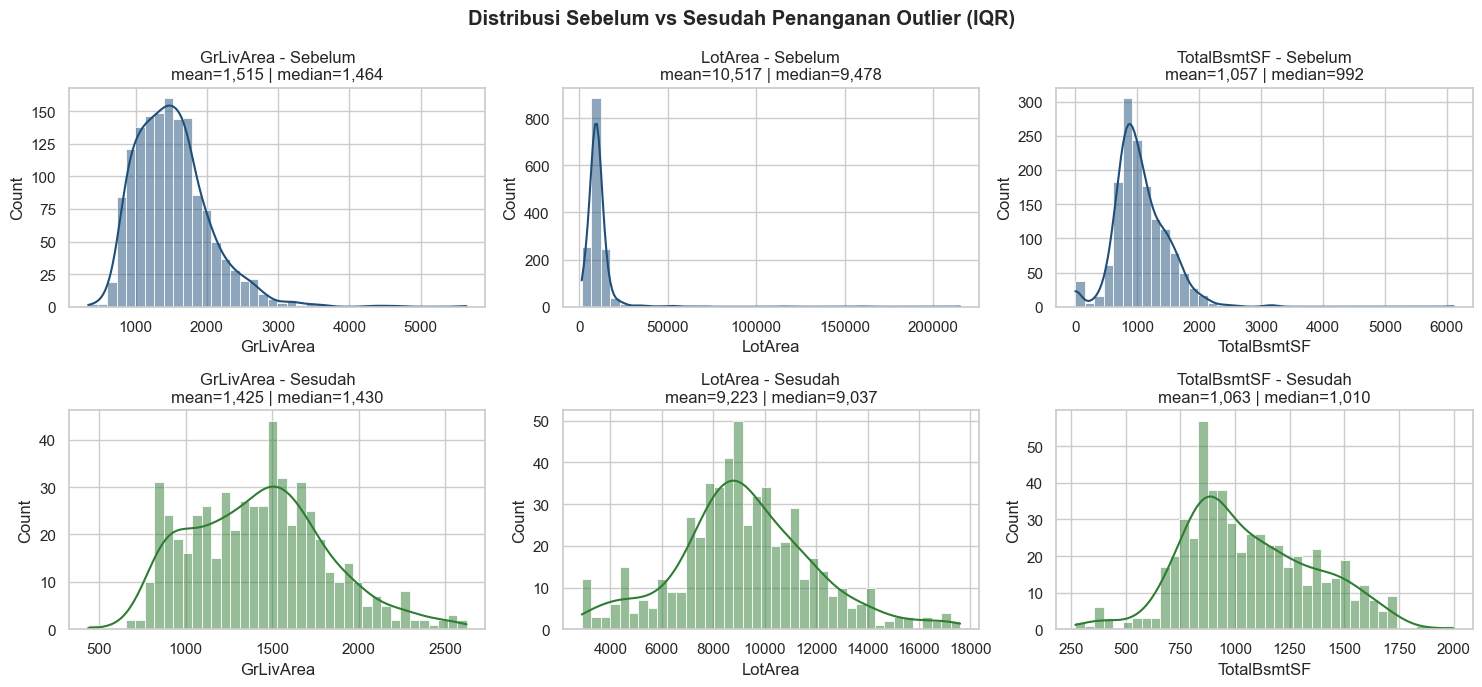

In [22]:
# Perbandingan distribusi sebelum vs sesudah penanganan outlier
kolom_banding = ["GrLivArea", "LotArea", "TotalBsmtSF"]
kolom_banding = [k for k in kolom_banding if k in df.columns]

fig, axes = plt.subplots(2, len(kolom_banding), figsize=(5 * len(kolom_banding), 7))

for j, kol in enumerate(kolom_banding):
    sns.histplot(train[kol].dropna(), bins=40, kde=True, ax=axes[0, j], color="#1f4e79")
    axes[0, j].set_title(f"{kol} - Sebelum\nmean={train[kol].mean():,.0f} | median={train[kol].median():,.0f}")

    sns.histplot(df[kol], bins=40, kde=True, ax=axes[1, j], color="#2e7d32")
    axes[1, j].set_title(f"{kol} - Sesudah\nmean={df[kol].mean():,.0f} | median={df[kol].median():,.0f}")

plt.suptitle("Distribusi Sebelum vs Sesudah Penanganan Outlier (IQR)", fontweight="bold")
plt.tight_layout()
plt.show()

**Hasil Penanganan Outlier:**
- Setelah outlier dihapus, rentang data menjadi lebih rapat dan distribusinya lebih teratur tanpa ekor nilai ekstrem yang terlalu panjang.
- *Trade-off:* Jumlah baris berkurang dari 1.460 menjadi 557 baris. Pada project riil, selain menghapus baris, alternatif lain adalah teknik *capping / winsorizing* (mengganti nilai ekstrem ke batas kuartil terdekat).

## 4. Normalisasi dan Standardisasi Data
Rentang nilai antar fitur pada dataset ini sangat bervariasi (contoh: `LotArea` bernilai puluhan ribu, sedangkan jumlah kamar hanya satuan).

**Pilihan Kami: Standardisasi (Z-Score)**
- **Alasan:** Algoritma regresi linier dan gradient-based bekerja lebih optimal jika fitur berdistribusi mendekati normal dengan mean $\approx 0$ dan standar deviasi $\approx 1$.
- **Rumus:** $z = \frac{x - \mu}{\sigma}$

### 4.1 Memeriksa Skala Fitur Numerik
Kita amati nilai min dan max dari masing-masing kolom numerik untuk melihat seberapa besar variasi skalanya.

In [23]:
# Cek skala fitur numerik sebelum scaling
skala_sebelum = pd.DataFrame({
    "min": df[numeric_features].min(),
    "max": df[numeric_features].max(),
    "mean": df[numeric_features].mean(),
    "std": df[numeric_features].std(),
})
skala_sebelum["rentang"] = skala_sebelum["max"] - skala_sebelum["min"]
skala_sebelum.round(2).sort_values("rentang", ascending=False).head(15)

,min,max,mean,std,rentang
SalePrice,37900.0,339750.0,178927.65,55267.72,301850.0
LotArea,2887.0,17600.0,9223.33,2723.09,14713.0
GrLivArea,438.0,2622.0,1425.28,392.87,2184.0
TotalBsmtSF,270.0,2000.0,1063.11,297.20,1730.0
1stFlrSF,438.0,2117.0,1116.79,289.41,1679.0
BsmtUnfSF,0.0,1670.0,618.38,424.86,1670.0
BsmtFinSF1,0.0,1619.0,444.73,408.97,1619.0
Id,1.0,1456.0,742.16,419.36,1455.0
2ndFlrSF,0.0,1349.0,308.49,415.29,1349.0
GarageArea,0.0,928.0,476.59,186.63,928.0


Terlihat rentang skala antar fitur sangat berbeda jauh, dari skala biner (0-1) hingga puluhan ribu (`LotArea`), sehingga standardisasi sangat diperlukan.

### 4.2 Standardisasi (StandardScaler / Z-Score)
Kita terapkan `StandardScaler()` pada seluruh fitur numerik agar skala datanya seragam.

In [24]:
# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

print("Standardisasi selesai.")
print(f"Mean seluruh fitur : {df[numeric_features].mean().mean():.6f}  (target ~0)")
print(f"Std seluruh fitur  : {df[numeric_features].std().mean():.6f}  (target ~1)")

Standardisasi selesai.
Mean seluruh fitur : 0.000000  (target ~0)
Std seluruh fitur  : 0.763844  (target ~1)


Kita siapkan fungsi visualisasi untuk membandingkan distribusi fitur sebelum vs sesudah standardisasi.

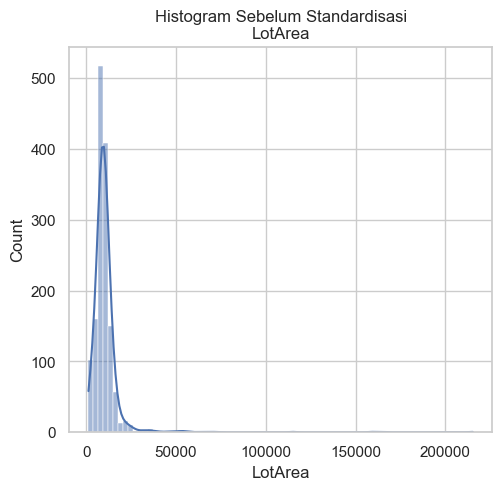

In [25]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title(f"Histogram Sebelum Standardisasi\n{numeric_features[3]}")
plt.show()

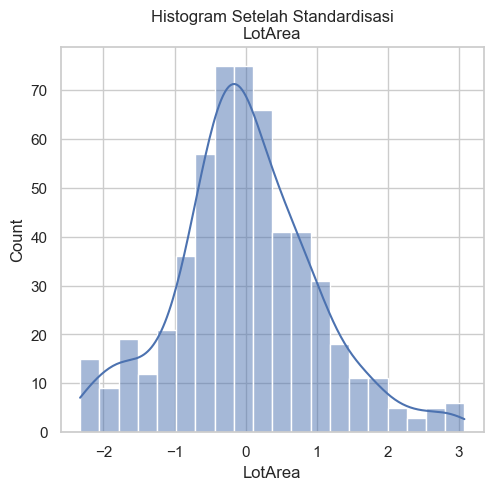

In [26]:
# Histogram Setelah Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title(f"Histogram Setelah Standardisasi\n{numeric_features[3]}")
plt.show()

Mari kita tampilkan plot distribusinya secara berdampingan.

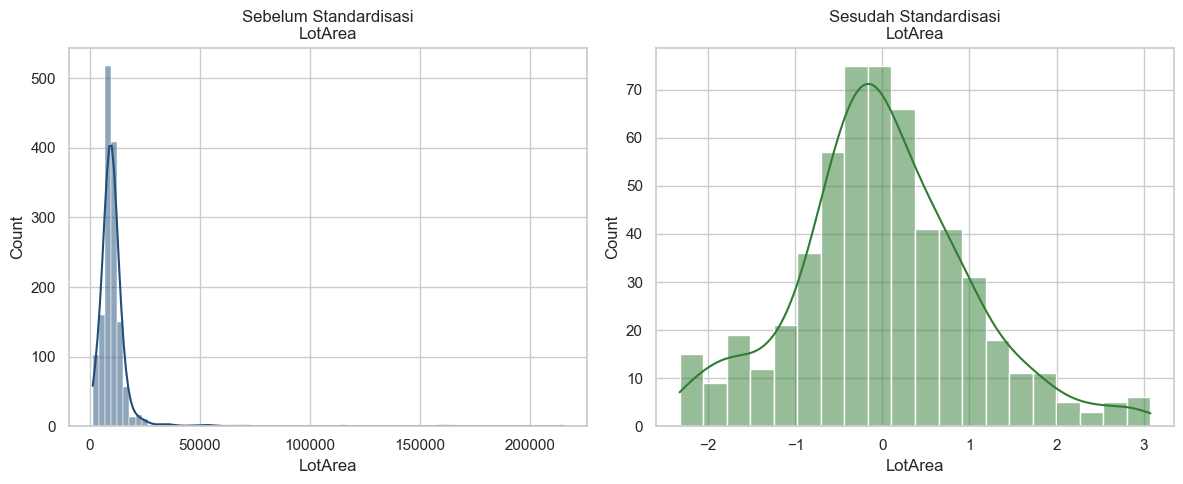

In [27]:
# Perbandingan berdampingan: sebelum vs sesudah
kolom_uji = numeric_features[3]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(train[kolom_uji], kde=True, ax=axes[0], color="#1f4e79")
axes[0].set_title(f"Sebelum Standardisasi\n{kolom_uji}")
sns.histplot(df[kolom_uji], kde=True, ax=axes[1], color="#2e7d32")
axes[1].set_title(f"Sesudah Standardisasi\n{kolom_uji}")
plt.tight_layout()
plt.show()

In [28]:
# Statistik perbandingan
kolom_uji = numeric_features[3]
pd.DataFrame({
    "sebelum": [train[kolom_uji].mean(), train[kolom_uji].std(), train[kolom_uji].min(), train[kolom_uji].max()],
    "sesudah": [df[kolom_uji].mean(), df[kolom_uji].std(), df[kolom_uji].min(), df[kolom_uji].max()],
}, index=["mean", "std", "min", "max"]).round(4)

,sebelum,sesudah
mean,10516.8281,0.0000
std,9981.2649,1.0009
min,1300.0000,-2.3290
max,215245.0000,3.0789


**Hasil Standardisasi:**
- Bentuk sebaran data tetap terjaga, namun sumbu nilainya kini terpusat di sekitar mean = 0 dan std = 1.
- Manfaatnya: mencegah fitur bernilai besar mendominasi fitur lain dan mempercepat konvergensi algoritma optimasi.

> **Catatan Pembelajaran (Best Practice):**  
> Pada latihan modul ini, standardisasi diterapkan langsung pada seluruh data untuk ilustrasi visual. Dalam pipeline machine learning produksi, scaling idealnya di-*fit* hanya pada data latih (train) lalu di-*transform* ke data uji (test) guna menghindari *data leakage*.

In [29]:
# Perbandingan ringkas: Min-Max Scaling vs StandardScaler
scaler_minmax = MinMaxScaler()
df_minmax = pd.DataFrame(
    scaler_minmax.fit_transform(df[numeric_features]),
    columns=numeric_features,
)

pd.DataFrame({
    "MinMaxScaler": [df_minmax.values.min(), df_minmax.values.max(),
                     df_minmax.values.mean(), df_minmax.values.std()],
    "StandardScaler": [df[numeric_features].values.min(), df[numeric_features].values.max(),
                       df[numeric_features].values.mean(), df[numeric_features].values.std()],
}, index=["min", "max", "mean", "std"]).round(4)

,MinMaxScaler,StandardScaler
min,0.0000,-3.4124
max,1.0000,3.4591
mean,0.3275,0.0000
std,0.3164,0.8736


## 5. Pemeriksaan Data Duplikat
Kita periksa apakah terdapat baris duplikat yang identik menggunakan fungsi `.duplicated()`.

In [30]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Id, MSSubClass, LotFrontage, LotArea, OverallQual, OverallCond, YearBuilt, YearRemodAdd, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, TotRmsAbvGrd, Fireplaces, GarageYrBlt, GarageCars, GarageArea, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, MoSold, YrSold, SalePrice, MSZoning, Street, LotShape, LandContour, Utilities, LotConfig, LandSlope, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, ExterQual, ExterCond, Foundation, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, Heating, HeatingQC, CentralAir, Electrical, KitchenQual, Functional, FireplaceQu, GarageType, GarageFinish, GarageQual, GarageCond, PavedDrive, SaleType, SaleCondition]
Index: []


**Hasil:** Tidak ditemukan baris duplikat pada dataset (`duplicated().sum() == 0`), sehingga seluruh baris bersifat unik dan kita bisa langsung lanjut ke tahap encoding.

In [31]:
# Menghapus baris duplikat (contoh saja — pada kasus ini tidak ada duplikat)
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print("Shape :", df.shape)

DataFrame setelah menghapus duplikat:
Shape : (557, 77)


*(Catatan: Jika ditemukan baris duplikat, kita dapat menghapusnya menggunakan `df.drop_duplicates()`)*.

## 6. Mengonversi Tipe Data (Feature Encoding)
Algoritma machine learning membutuhkan input numerik, sehingga kolom bertipe kategorikal (`object`) harus dikonversi menjadi angka.

Dua metode yang kami pelajari:
1. **One-Hot Encoding (`pd.get_dummies`):** Membuat kolom biner (0/1) untuk setiap kategori unik. Cocok untuk data nominal tanpa tingkatan, namun menambah banyak kolom baru.
2. **Label Encoding (`LabelEncoder`):** Mengubah tiap kategori menjadi integer berurutan (0, 1, 2, ...). Tidak menambah jumlah kolom.

In [32]:
category_features = df.select_dtypes(include=["object"]).columns
df[category_features].head(10)

,MSZoning,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,Heating,HeatingQC,CentralAir,Electrical,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,SaleType,SaleCondition
0,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,Gable,CompShg,VinylSd,VinylSd,BrkFace,Gd,TA,PConc,Gd,TA,No,GLQ,Unf,GasA,Ex,Y,SBrkr,Gd,Typ,Gd,Attchd,RFn,TA,TA,Y,WD,Normal
2,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,Gable,CompShg,VinylSd,VinylSd,BrkFace,Gd,TA,PConc,Gd,TA,Mn,GLQ,Unf,GasA,Ex,Y,SBrkr,Gd,Typ,TA,Attchd,RFn,TA,TA,Y,WD,Normal
4,RL,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,Gable,CompShg,VinylSd,VinylSd,BrkFace,Gd,TA,PConc,Gd,TA,Av,GLQ,Unf,GasA,Ex,Y,SBrkr,Gd,Typ,TA,Attchd,RFn,TA,TA,Y,WD,Normal
6,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,1Fam,1Story,Gable,CompShg,VinylSd,VinylSd,Stone,Gd,TA,PConc,Ex,TA,Av,GLQ,Unf,GasA,Ex,Y,SBrkr,Gd,Typ,Gd,Attchd,RFn,TA,TA,Y,WD,Normal
10,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,Norm,1Fam,1Story,Hip,CompShg,HdBoard,HdBoard,BrkFace,TA,TA,CBlock,TA,TA,No,Rec,Unf,GasA,Ex,Y,SBrkr,TA,Typ,Gd,Detchd,Unf,TA,TA,Y,WD,Normal
13,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,1Story,Gable,CompShg,VinylSd,VinylSd,Stone,Gd,TA,PConc,Gd,TA,Av,Unf,Unf,GasA,Ex,Y,SBrkr,Gd,Typ,Gd,Attchd,RFn,TA,TA,Y,New,Partial
18,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,SawyerW,RRAe,Norm,1Fam,1Story,Gable,CompShg,VinylSd,VinylSd,BrkFace,TA,TA,PConc,TA,TA,No,GLQ,Unf,GasA,Ex,Y,SBrkr,Gd,Typ,Gd,Detchd,Unf,TA,TA,Y,WD,Normal
19,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,Hip,CompShg,BrkFace,Plywood,BrkFace,TA,TA,CBlock,TA,TA,No,LwQ,Unf,GasA,TA,Y,SBrkr,TA,Min1,Gd,Attchd,Unf,TA,TA,Y,COD,Abnorml
20,RL,Pave,IR1,Lvl,AllPub,Corner,Gtl,NridgHt,Norm,Norm,1Fam,2Story,Gable,CompShg,VinylSd,VinylSd,BrkFace,Gd,TA,PConc,Ex,TA,Av,Unf,Unf,GasA,Ex,Y,SBrkr,Gd,Typ,Gd,BuiltIn,RFn,TA,TA,Y,New,Partial
23,RM,Pave,Reg,Lvl,AllPub,Inside,Gtl,MeadowV,Norm,Norm,TwnhsE,1Story,Gable,CompShg,CemntBd,CmentBd,BrkFace,TA,TA,PConc,Gd,TA,No,GLQ,Unf,GasA,TA,Y,SBrkr,TA,Typ,TA,Attchd,Unf,TA,TA,Y,WD,Normal


In [33]:
ringkasan_kategori = pd.DataFrame({
    "jumlah_unik": [df[c].nunique() for c in category_features],
    "contoh_nilai": [", ".join(df[c].dropna().unique()[:4].astype(str)) for c in category_features],
}, index=list(category_features))

print("Jumlah kolom kategorikal :", len(category_features))
print("Total kategori unik      :", ringkasan_kategori["jumlah_unik"].sum())
ringkasan_kategori

Jumlah kolom kategorikal : 39
Total kategori unik      : 178


,jumlah_unik,contoh_nilai
MSZoning,4,"RL, RM, FV, RH"
Street,2,"Pave, Grvl"
LotShape,4,"Reg, IR1, IR3, IR2"
LandContour,4,"Lvl, Bnk, HLS, Low"
Utilities,1,AllPub
LotConfig,5,"Inside, FR2, Corner, CulDSac"
LandSlope,2,"Gtl, Mod"
Neighborhood,23,"CollgCr, NoRidge, Somerst, Sawyer"
Condition1,7,"Norm, RRAe, Artery, Feedr"
Condition2,1,Norm


### 6.1 Uji Coba One-Hot Encoding
Pertama, kita uji konversi fitur kategorikal dengan One-Hot Encoding.

In [34]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice,MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,Street_Grvl,Street_Pave,LotShape_IR1,LotShape_IR2,LotShape_IR3,LotShape_Reg,LandContour_Bnk,LandContour_HLS,...,CentralAir_N,CentralAir_Y,Electrical_FuseA,Electrical_FuseF,Electrical_SBrkr,KitchenQual_Ex,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA,Functional_Maj1,Functional_Maj2,Functional_Min1,Functional_Min2,Functional_Typ,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_Po,FireplaceQu_TA,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_Detchd,GarageFinish_Fin,GarageFinish_RFn,GarageFinish_Unf,GarageQual_Fa,GarageQual_Gd,GarageQual_TA,GarageCond_Fa,GarageCond_Gd,GarageCond_Po,GarageCond_TA,PavedDrive_N,PavedDrive_P,PavedDrive_Y,SaleType_COD,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,-1.768952,0.356986,-0.265012,-0.284244,0.614520,-0.523677,0.784193,0.704506,1.183911,0.639427,0.0,-1.103434,-0.697482,-0.901932,1.314747,0.0,0.725374,1.157781,0.0,0.787362,1.266019,0.294737,0.0,1.291657,-0.944263,0.771906,0.273711,0.383002,-0.923836,0.439408,0.0,0.0,0.0,0.0,0.0,-1.633929,0.161764,0.535556,False,False,True,False,False,True,False,False,False,True,False,False,...,False,True,False,False,True,False,False,True,False,False,False,False,False,True,False,False,True,False,False,True,False,False,False,False,True,False,False,False,True,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True,False
2,-1.764179,0.356986,-0.037099,0.744924,0.614520,-0.523677,0.704296,0.653431,0.856804,0.101006,0.0,-0.434370,-0.481947,-0.680593,1.343668,0.0,0.918998,1.157781,0.0,0.787362,1.266019,0.294737,0.0,-0.235844,0.785851,0.681055,0.273711,0.704787,-0.923836,0.017501,0.0,0.0,0.0,0.0,0.0,1.006224,0.161764,0.807206,False,False,True,False,False,True,True,False,False,False,False,False,...,False,True,False,False,True,False,False,True,False,False,False,False,False,True,False,False,False,False,True,True,False,False,False,False,True,False,False,False,True,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True,False
4,-1.759405,0.356986,1.178437,1.851281,1.419903,-0.523677,0.664347,0.551281,2.665515,0.514611,0.0,-0.302442,0.275791,0.097550,1.794358,0.0,1.968640,1.157781,0.0,0.787362,1.266019,1.814814,0.0,2.055408,0.785851,0.635629,1.768390,1.927567,1.035252,0.950138,0.0,0.0,0.0,0.0,0.0,2.137718,0.161764,1.287121,False,False,True,False,False,True,True,False,False,False,False,False,...,False,True,False,False,True,False,False,True,False,False,False,False,False,True,False,False,False,False,True,True,False,False,False,False,True,False,False,False,True,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True,False
6,-1.754632,-0.917637,0.494698,0.316349,1.419903,-0.523677,0.824141,0.806656,1.087703,2.262035,0.0,-0.710006,2.097729,1.996219,-0.743486,0.0,0.684611,1.157781,0.0,0.787362,-0.789878,0.294737,0.0,0.527907,0.785851,0.817331,0.273711,0.854953,1.678077,0.350586,0.0,0.0,0.0,0.0,0.0,0.629059,-0.595399,2.319391,False,False,True,False,False,True,False,False,False,True,False,False,...,False,True,False,False,True,False,False,True,False,False,False,False,False,True,False,False,True,False,False,True,False,False,False,False,True,False,False,False,True,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,True,False,False,

Kita terapkan `pd.get_dummies()` pada semua kolom kategori.

In [35]:
print("Shape sebelum one hot encoding :", df.shape)
print("Shape sesudah one hot encoding :", df_one_hot.shape)
print()
print("Contoh nama kolom baru:")
print([c for c in df_one_hot.columns if "_" in c and c.split("_")[0] in list(category_features)][:12])

Shape sebelum one hot encoding : (557, 77)
Shape sesudah one hot encoding : (557, 216)

Contoh nama kolom baru:
['MSZoning_FV', 'MSZoning_RH', 'MSZoning_RL', 'MSZoning_RM', 'Street_Grvl', 'Street_Pave', 'LotShape_IR1', 'LotShape_IR2', 'LotShape_IR3', 'LotShape_Reg', 'LandContour_Bnk', 'LandContour_HLS']


In [36]:
# Cek tipe data setelah one hot encoding
print("Jumlah kolom numerik setelah OHE :", df_one_hot.select_dtypes(include=[np.number]).shape[1])
print("Jumlah kolom object setelah OHE  :", df_one_hot.select_dtypes(include=["object"]).shape[1])

Jumlah kolom numerik setelah OHE : 38
Jumlah kolom object setelah OHE  : 0


**Hasil One-Hot Encoding:** Jumlah kolom melonjak drastis dari 77 menjadi ratusan kolom karena setiap kategori dipecah menjadi kolom baru.

### 6.2 Uji Coba Label Encoding
Sebagai alternatif yang lebih hemat dimensi, kita coba gunakan `LabelEncoder` dari scikit-learn.

In [37]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice,MSZoning,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,Heating,HeatingQC,CentralAir,Electrical,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,SaleType,SaleCondition
0,-1.768952,0.356986,-0.265012,-0.284244,0.614520,-0.523677,0.784193,0.704506,1.183911,0.639427,0.0,-1.103434,-0.697482,-0.901932,1.314747,0.0,0.725374,1.157781,0.0,0.787362,1.266019,0.294737,0.0,1.291657,-0.944263,0.771906,0.273711,0.383002,-0.923836,0.439408,0.0,0.0,0.0,0.0,0.0,-1.633929,0.161764,0.535556,2,1,3,3,0,4,0,3,2,0,0,3,0,0,7,9,1,2,2,2,2,2,3,2,0,0,0,1,2,2,4,2,0,1,2,3,2,8,3
2,-1.764179,0.356986,-0.037099,0.744924,0.614520,-0.523677,0.704296,0.653431,0.856804,0.101006,0.0,-0.434370,-0.481947,-0.680593,1.343668,0.0,0.918998,1.157781,0.0,0.787362,1.266019,0.294737,0.0,-0.235844,0.785851,0.681055,0.273711,0.704787,-0.923836,0.017501,0.0,0.0,0.0,0.0,0.0,1.006224,0.161764,0.807206,2,1,0,3,0,4,0,3,2,0,0,3,0,0,7,9,1,2,2,2,2,2,2,2,0,0,0,1,2,2,4,4,0,1,2,3,2,8,3
4,-1.759405,0.356986,1.178437,1.851281,1.419903,-0.523677,0.664347,0.551281,2.665515,0.514611,0.0,-0.302442,0.275791,0.097550,1.794358,0.0,1.968640,1.157781,0.0,0.787362,1.266019,1.814814,0.0,2.055408,0.785851,0.635629,1.768390,1.927567,1.035252,0.950138,0.0,0.0,0.0,0.0,0.0,2.137718,0.161764,1.287121,2,1,0,3,0,2,0,13,2,0,0,3,0,0,7,9,1,2,2,2,2,2,0,2,0,0,0,1,2,2,4,4,0,1,2,3,2,8,3
6,-1.754632,-0.917637,0.494698,0.316349,1.419903,-0.523677,0.824141,0.806656,1.087703,2.262035,0.0,-0.710006,2.097729,1.996219,-0.743486,0.0,0.684611,1.157781,0.0,0.787362,-0.789878,0.294737,0.0,0.527907,0.785851,0.817331,0.273711,0.854953,1.678077,0.350586,0.0,0.0,0.0,0.0,0.0,0.629059,-0.595399,2.319391,2,1,3,3,0,4,0,19,2,0,0,2,0,0,7,9,2,2,2,2,0,2,0,2,0,0,0,1,2,2,4,2,0,1,2,3,2,8,3
10,-1.745085,-0.917637,0.114843,0.726546,-0.996245,-0.523677,-0.733845,-1.236347,-0.701766,1.128902,0.0,-1.141128,-0.077820,-0.265584,-0.743486,0.0,-0.981569,1.157781,0.0,-1.215199,-0.789878,0.294737,0.0,-0.999595,-0.944263,-0.954260,-1.220967,-0.496542,-0.923836,-0.915135,0.0,0.0,0.0,0.0,0.0,-1.633929,0.161764,-0.895135,2,1,3,3,0,4,0,17,2,0,0,2,2,0,3,3,1,3,2,1,3,2,3,4,0,0,0,1,2,3,4,2,3,2,2,3,2,8,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1448,1.687057,0.038330,0.114843,0.934953,-1.801628,2.308244,-2.931004,0.551281,-0.701766,-1.088417,0.0,-0.137532,-1.694328,-1.109437,0.582074,0.0,-0.201980,-0.851204,0.0,-1.215199,1.266019,-1.225341,0.0,-0.235844,-0.944263,-1.635641,-1.220967,-0.496542,0.790366,-0.382200,0.0,0.0,0.0,0.0,0.0,-0.502435,-0.595399,-1.212060,2,1,3,3,0,4,0,5,2,0,0,3,0,0,4,3,1,3,2,1,1,2,3,5,0,0,2,0,2,3,3,2,3,2,0,3,2,8,3
1451,1.694217,-0.917637,0.722611,0.014215,1.419903,-0.523677,0.983934,1.010957,1.164670,-1.088417,0.0,2.248952,1.717176,1.595043,-0.743486,0.0,0.389081,-0.851204,0.0,0.787362,-0.789878,0.294737,0.0,0.527907,0.785851,0.999033,1.768390,1.949020,-0.923836,-0.115732,0.0,0.0,0.0,0.0,0.0,-0.502435,0.918926,1.958821,2,1,3,3,0,4,0,19,2,0,0,2,0,0,2,2,2,2,2,2,2,2,3,5,0,0,0,1,2,0,4,2,0,0,2,3,2,6,4
1453,1.698991,-0.917637,1.634263,2.938156,-0.996245,-0.523677,0.904038,0.857731,-0.701766,-1.088417,0.0,1.228865,0.258952,0.080258,-0

**Hasil Label Encoding:** Jumlah kolom tetap sama (77 kolom), hanya nilainya yang berubah menjadi integer representatif.

In [38]:
print("Shape sebelum label encoding :", df.shape)
print("Shape sesudah label encoding :", df_lencoder.shape)
print()
print("Tipe data setelah label encoding:")
print(df_lencoder.dtypes.value_counts())

Shape sebelum label encoding : (557, 77)
Shape sesudah label encoding : (557, 77)

Tipe data setelah label encoding:
int64      39
float64    38
Name: count, dtype: int64


In [39]:
# Contoh pemetaan label pada satu kolom
contoh_kolom = category_features[0]
encoder_contoh = LabelEncoder().fit(df[contoh_kolom])

pd.DataFrame({
    "kategori": encoder_contoh.classes_,
    "label": range(len(encoder_contoh.classes_)),
})

,kategori,label
0,FV,0
1,RH,1
2,RL,2
3,RM,3


### 6.3 Kesimpulan Pemilihan Encoder
Berdasarkan perbandingan kami:
- **One-Hot Encoding** sangat baik untuk fitur nominal berkardinalitas rendah agar model tidak salah mengartikan angka sebagai urutan tingkatan.
- **Label Encoding** menjaga dataset tetap ringkas dan hemat memori pada dataset dengan banyak fitur kategorikal.
- Untuk kelanjutan proyek ini, kita menggunakan dataframe hasil **Label Encoding (`df_lencoder`)** agar dimensi data tetap terkendali (77 kolom).

In [40]:
# DataFrame akhir setelah seluruh tahapan cleaning & transformation
print("Shape DataFrame akhir :", df_lencoder.shape)
print("Seluruh kolom numerik :", df_lencoder.select_dtypes(include=[np.number]).shape[1] == df_lencoder.shape[1])
print()
df_lencoder.head()

Shape DataFrame akhir : (557, 77)
Seluruh kolom numerik : True



,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice,MSZoning,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,Heating,HeatingQC,CentralAir,Electrical,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,SaleType,SaleCondition
0,-1.768952,0.356986,-0.265012,-0.284244,0.614520,-0.523677,0.784193,0.704506,1.183911,0.639427,0.0,-1.103434,-0.697482,-0.901932,1.314747,0.0,0.725374,1.157781,0.0,0.787362,1.266019,0.294737,0.0,1.291657,-0.944263,0.771906,0.273711,0.383002,-0.923836,0.439408,0.0,0.0,0.0,0.0,0.0,-1.633929,0.161764,0.535556,2,1,3,3,0,4,0,3,2,0,0,3,0,0,7,9,1,2,2,2,2,2,3,2,0,0,0,1,2,2,4,2,0,1,2,3,2,8,3
2,-1.764179,0.356986,-0.037099,0.744924,0.614520,-0.523677,0.704296,0.653431,0.856804,0.101006,0.0,-0.434370,-0.481947,-0.680593,1.343668,0.0,0.918998,1.157781,0.0,0.787362,1.266019,0.294737,0.0,-0.235844,0.785851,0.681055,0.273711,0.704787,-0.923836,0.017501,0.0,0.0,0.0,0.0,0.0,1.006224,0.161764,0.807206,2,1,0,3,0,4,0,3,2,0,0,3,0,0,7,9,1,2,2,2,2,2,2,2,0,0,0,1,2,2,4,4,0,1,2,3,2,8,3
4,-1.759405,0.356986,1.178437,1.851281,1.419903,-0.523677,0.664347,0.551281,2.665515,0.514611,0.0,-0.302442,0.275791,0.097550,1.794358,0.0,1.968640,1.157781,0.0,0.787362,1.266019,1.814814,0.0,2.055408,0.785851,0.635629,1.768390,1.927567,1.035252,0.950138,0.0,0.0,0.0,0.0,0.0,2.137718,0.161764,1.287121,2,1,0,3,0,2,0,13,2,0,0,3,0,0,7,9,1,2,2,2,2,2,0,2,0,0,0,1,2,2,4,4,0,1,2,3,2,8,3
6,-1.754632,-0.917637,0.494698,0.316349,1.419903,-0.523677,0.824141,0.806656,1.087703,2.262035,0.0,-0.710006,2.097729,1.996219,-0.743486,0.0,0.684611,1.157781,0.0,0.787362,-0.789878,0.294737,0.0,0.527907,0.785851,0.817331,0.273711,0.854953,1.678077,0.350586,0.0,0.0,0.0,0.0,0.0,0.629059,-0.595399,2.319391,2,1,3,3,0,4,0,19,2,0,0,2,0,0,7,9,2,2,2,2,0,2,0,2,0,0,0,1,2,2,4,2,0,1,2,3,2,8,3
10,-1.745085,-0.917637,0.114843,0.726546,-0.996245,-0.523677,-0.733845,-1.236347,-0.701766,1.128902,0.0,-1.141128,-0.077820,-0.265584,-0.743486,0.0,-0.981569,1.157781,0.0,-1.215199,-0.789878,0.294737,0.0,-0.999595,-0.944263,-0.954260,-1.220967,-0.496542,-0.923836,-0.915135,0.0,0.0,0.0,0.0,0.0,-1.633929,0.161764,-0.895135,2,1,3,3,0,4,0,17,2,0,0,2,2,0,3,3,1,3,2,1,3,2,3,4,0,0,0,1,2,3,4,2,3,2,2,3,2,8,3


---
# Bagian II: Exploratory Data Analysis (EDA) & Pemodelan
Setelah data bersih dan seluruh fitur berbentuk numerik, kita melangkah ke analisis pola sebaran, korelasi fitur dengan target harga (`SalePrice`), serta pelatihan model regresi.

## 8. Verifikasi Data Siap Pakai
Kita pastikan kembali kondisi dataframe `df_lencoder` yang akan digunakan: memastikan tidak ada missing value yang tertinggal dan seluruh kolom sudah numerik.

In [41]:
df_lencoder.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice,MSZoning,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,Heating,HeatingQC,CentralAir,Electrical,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,SaleType,SaleCondition
0,-1.768952,0.356986,-0.265012,-0.284244,0.614520,-0.523677,0.784193,0.704506,1.183911,0.639427,0.0,-1.103434,-0.697482,-0.901932,1.314747,0.0,0.725374,1.157781,0.0,0.787362,1.266019,0.294737,0.0,1.291657,-0.944263,0.771906,0.273711,0.383002,-0.923836,0.439408,0.0,0.0,0.0,0.0,0.0,-1.633929,0.161764,0.535556,2,1,3,3,0,4,0,3,2,0,0,3,0,0,7,9,1,2,2,2,2,2,3,2,0,0,0,1,2,2,4,2,0,1,2,3,2,8,3
2,-1.764179,0.356986,-0.037099,0.744924,0.614520,-0.523677,0.704296,0.653431,0.856804,0.101006,0.0,-0.434370,-0.481947,-0.680593,1.343668,0.0,0.918998,1.157781,0.0,0.787362,1.266019,0.294737,0.0,-0.235844,0.785851,0.681055,0.273711,0.704787,-0.923836,0.017501,0.0,0.0,0.0,0.0,0.0,1.006224,0.161764,0.807206,2,1,0,3,0,4,0,3,2,0,0,3,0,0,7,9,1,2,2,2,2,2,2,2,0,0,0,1,2,2,4,4,0,1,2,3,2,8,3
4,-1.759405,0.356986,1.178437,1.851281,1.419903,-0.523677,0.664347,0.551281,2.665515,0.514611,0.0,-0.302442,0.275791,0.097550,1.794358,0.0,1.968640,1.157781,0.0,0.787362,1.266019,1.814814,0.0,2.055408,0.785851,0.635629,1.768390,1.927567,1.035252,0.950138,0.0,0.0,0.0,0.0,0.0,2.137718,0.161764,1.287121,2,1,0,3,0,2,0,13,2,0,0,3,0,0,7,9,1,2,2,2,2,2,0,2,0,0,0,1,2,2,4,4,0,1,2,3,2,8,3
6,-1.754632,-0.917637,0.494698,0.316349,1.419903,-0.523677,0.824141,0.806656,1.087703,2.262035,0.0,-0.710006,2.097729,1.996219,-0.743486,0.0,0.684611,1.157781,0.0,0.787362,-0.789878,0.294737,0.0,0.527907,0.785851,0.817331,0.273711,0.854953,1.678077,0.350586,0.0,0.0,0.0,0.0,0.0,0.629059,-0.595399,2.319391,2,1,3,3,0,4,0,19,2,0,0,2,0,0,7,9,2,2,2,2,0,2,0,2,0,0,0,1,2,2,4,2,0,1,2,3,2,8,3
10,-1.745085,-0.917637,0.114843,0.726546,-0.996245,-0.523677,-0.733845,-1.236347,-0.701766,1.128902,0.0,-1.141128,-0.077820,-0.265584,-0.743486,0.0,-0.981569,1.157781,0.0,-1.215199,-0.789878,0.294737,0.0,-0.999595,-0.944263,-0.954260,-1.220967,-0.496542,-0.923836,-0.915135,0.0,0.0,0.0,0.0,0.0,-1.633929,0.161764,-0.895135,2,1,3,3,0,4,0,17,2,0,0,2,2,0,3,3,1,3,2,1,3,2,3,4,0,0,0,1,2,3,4,2,3,2,2,3,2,8,3


### 8.1 Cek Ulang Missing Value
Kita verifikasi sekali lagi apakah masih ada nilai `NaN` yang tersisa.

In [42]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]  # Menampilkan kolom dengan missing values

,Missing Values,Percentage


**Hasil Verifikasi:** Missing value sudah **0 (bersih 100%)**. Data siap untuk analisis distribusi dan pemodelan.

In [43]:
print("Total missing value pada df_lencoder :", int(df_lencoder.isnull().sum().sum()))
print("Shape df_lencoder                    :", df_lencoder.shape)

Total missing value pada df_lencoder : 0
Shape df_lencoder                    : (557, 77)


## 9. Analisis Distribusi Data
Kita ingin melihat bagaimana sebaran data pada fitur-fitur yang ada, baik dari ringkasan statistik maupun visualisasi histogram.

In [44]:
df_lencoder.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,557.0,5.102641e-17,1.000899,-1.768952,-0.845281,0.047362,0.861243,1.703764
MSSubClass,557.0,7.175589e-17,1.000899,-0.917637,-0.917637,0.038330,0.356986,2.268921
LotFrontage,557.0,-5.102641e-16,1.000899,-2.772055,-0.568896,0.038872,0.494698,2.925770
LotArea,557.0,3.236988e-16,1.000899,-2.328982,-0.541536,-0.068486,0.579522,3.078932
OverallQual,557.0,2.328080e-16,1.000899,-3.412393,-0.996245,-0.190863,0.614520,3.030668
...,...,...,...,...,...,...,...,...
GarageQual,557.0,1.947935e+00,0.315915,0.000000,2.000000,2.000000,2.000000,2.000000
GarageCond,557.0,2.958707e+00,0.334068,0.000000,3.000000,3.000000,3.000000,3.000000
PavedDrive,557.0,1.942549e+00,0.317821,0.000000,2.000000,2.000000,2.000000,2.000000
SaleType,557.0,7.475763e+00,1.519018,0.000000,8.000000,8.000000,8.000000,8.000000


### 9.1 Visualisasi Sebaran Seluruh Kolom
Kita plot histogram untuk melihat gambaran umum distribusi seluruh fitur dalam dataset.

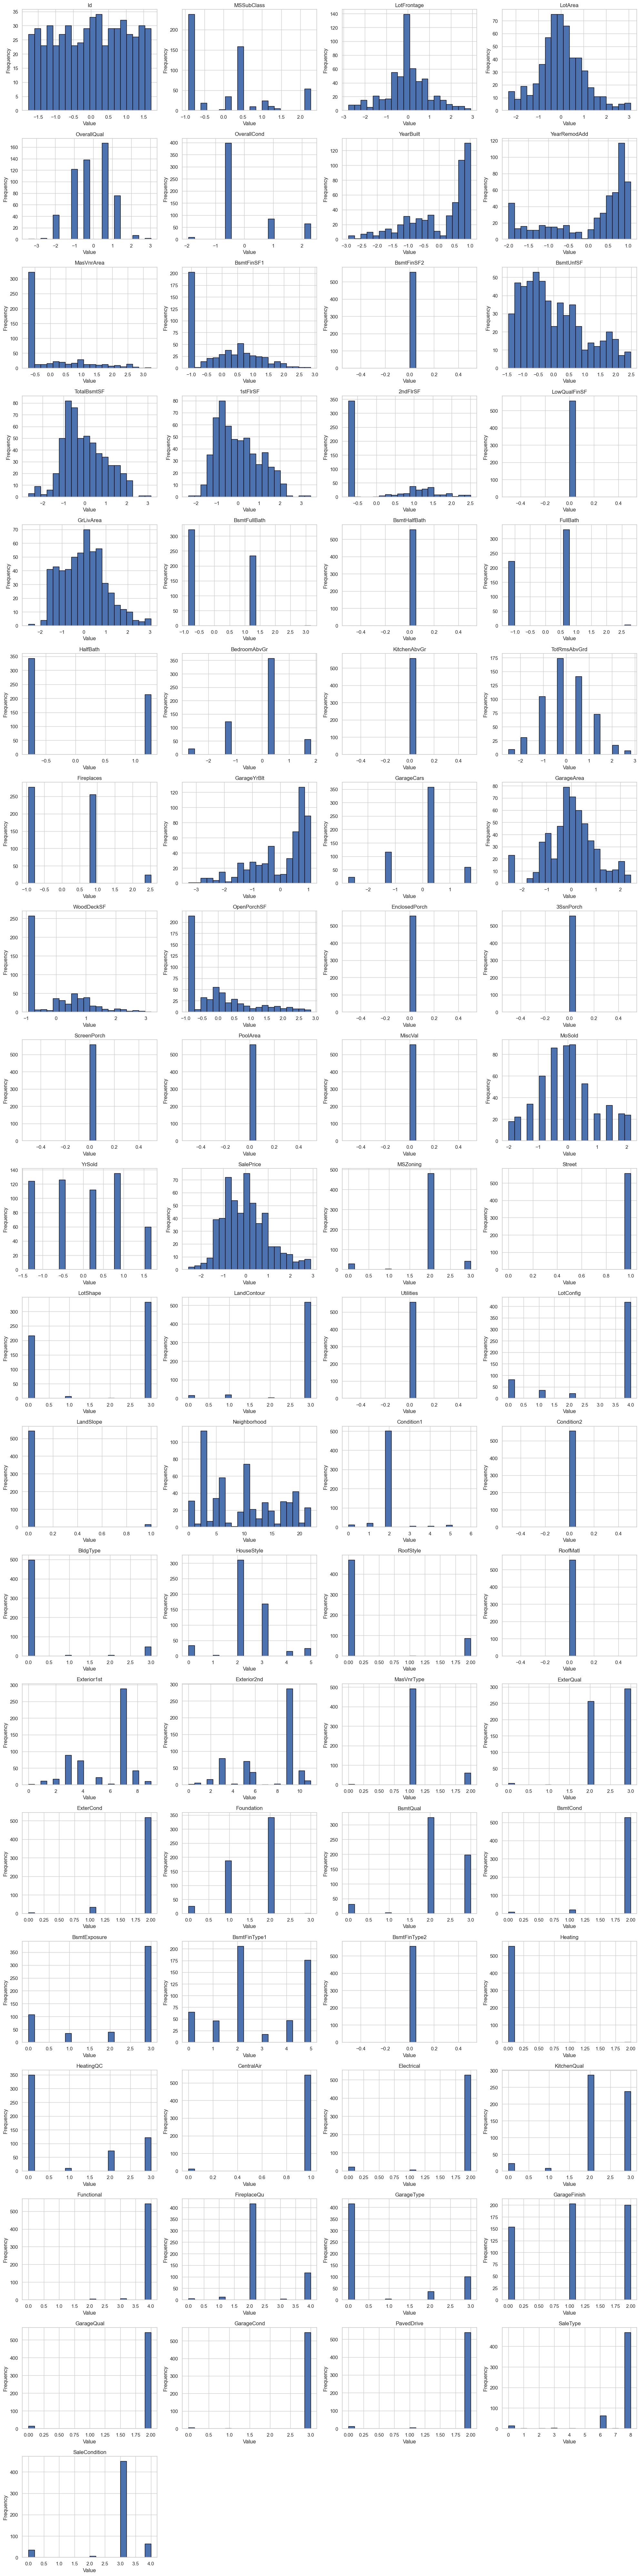

In [45]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4  # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols)  # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

**Temuan Distribusi:** Sebagian besar fitur numerik memiliki mean mendekati 0 dan varians teratur karena efek standardisasi yang telah dilakukan sebelumnya.

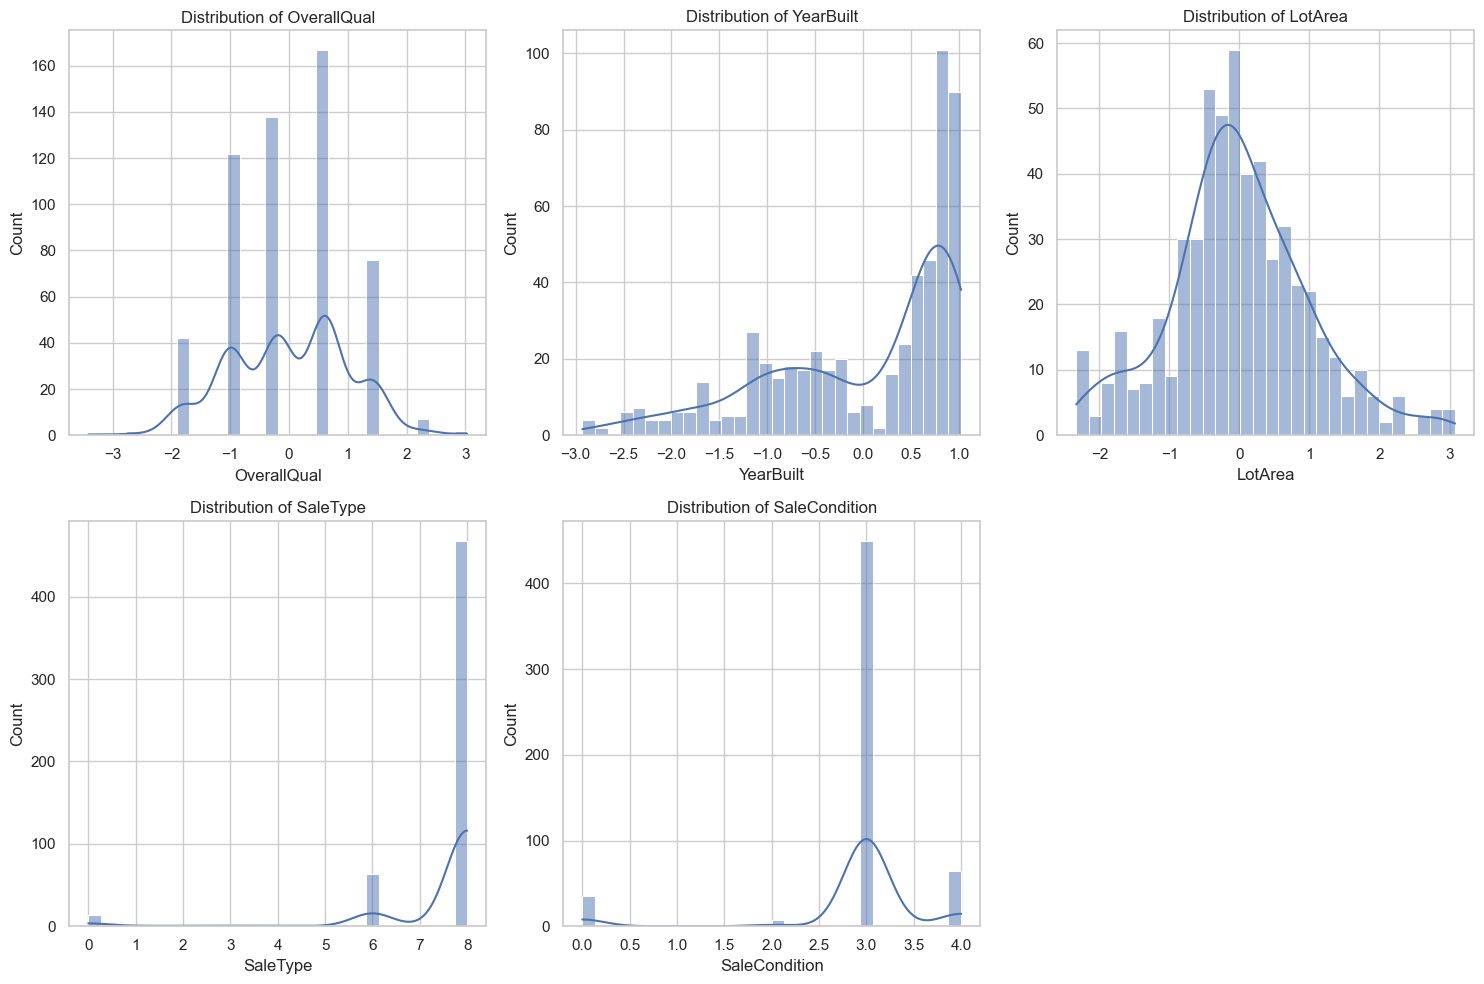

In [46]:
# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = ['OverallQual', 'YearBuilt', 'LotArea', 'SaleType', 'SaleCondition']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

### 9.2 Karakteristik Fitur Kunci
Dari visualisasi beberapa fitur utama:
- **`OverallQual`:** Memiliki pola beberapa puncak (*multimodal*), mencerminkan tingkatan kualitas bangunan dari standar hingga mewah.
- **`YearBuilt`:** Condong ke kanan (*left-skewed*), menunjukkan populasi rumah yang dibangun pada dekade modern lebih banyak dibanding rumah tua.
- **`LotArea`:** Distribusi terpusat rapat dengan beberapa variasi luas tanah.
- **`SaleType` & `SaleCondition`:** Didominasi oleh pola transaksi normal/standar.

## 10. Analisis Korelasi Antar Fitur
Kita hitung korelasi Pearson untuk melihat keeratan hubungan linier antar fitur, terutama terhadap variabel target (`SalePrice`).

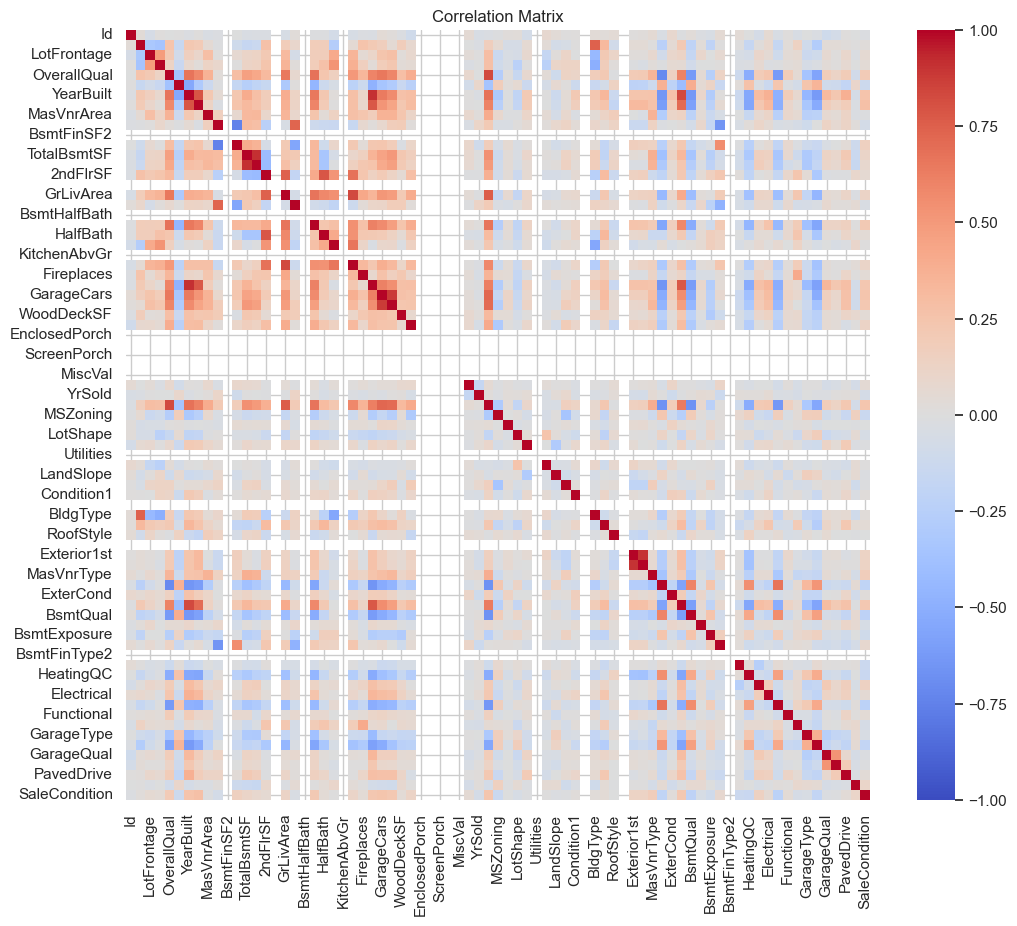

In [47]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

**Prinsip Korelasi Pearson:**
- Nilai mendekati **+1**: Hubungan linier positif kuat (fitur naik, harga ikut naik).
- Nilai mendekati **-1**: Hubungan linier negatif kuat (fitur naik, harga turun).
- Nilai mendekati **0**: Tidak ada hubungan linier langsung.

### 10.1 Fitur yang Paling Berpengaruh Terhadap `SalePrice`
Kita filter korelasi secara khusus terhadap variabel target (`SalePrice`) untuk menemukan fitur penentu utama harga rumah.

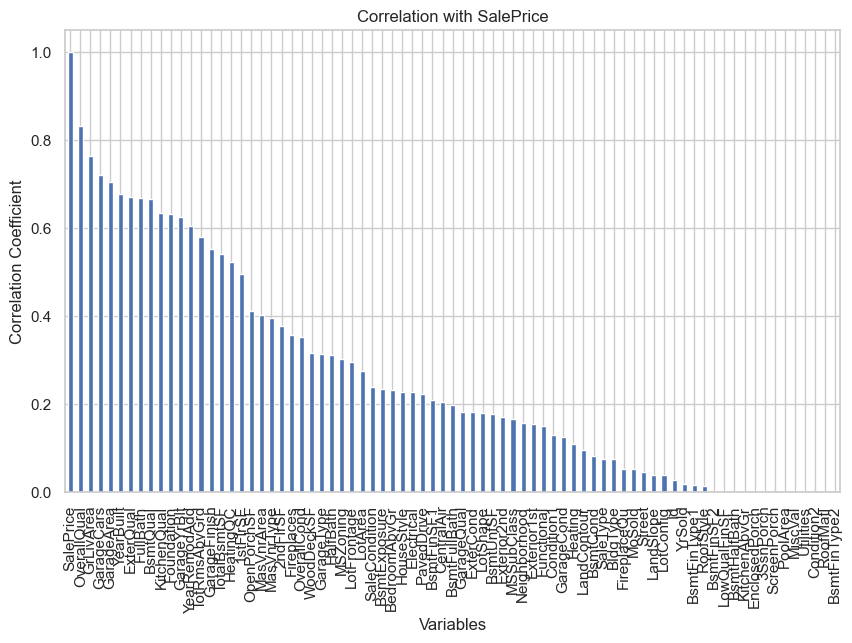

In [48]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['SalePrice']

# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with SalePrice')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

Kita urutkan fitur berdasarkan kekuatan korelasinya terhadap `SalePrice`.

In [49]:
# Nilai korelasi terhadap SalePrice (diurutkan)
target_corr_urut = target_corr.drop('SalePrice').sort_values(key=lambda s: s.abs(), ascending=False)

pd.DataFrame({
    'korelasi': target_corr_urut,
    'abs_korelasi': target_corr_urut.abs(),
}).round(4)

,korelasi,abs_korelasi
OverallQual,0.8323,0.8323
GrLivArea,0.7628,0.7628
GarageCars,0.7206,0.7206
GarageArea,0.7040,0.7040
YearBuilt,0.6778,0.6778
...,...,...
MiscVal,NaN,NaN
Utilities,NaN,NaN
Condition2,NaN,NaN
RoofMatl,NaN,NaN


In [50]:
# Menerapkan threshold korelasi untuk seleksi fitur
threshold_list = [0.1, 0.2, 0.3, 0.5]

ringkasan_threshold = pd.DataFrame({
    'threshold': threshold_list,
    'jumlah_fitur_terpilih': [
        int((target_corr.drop('SalePrice').abs() >= t).sum()) for t in threshold_list
    ],
})

print("Jumlah total fitur (di luar SalePrice) :", df_lencoder.shape[1] - 1)
print()
ringkasan_threshold

Jumlah total fitur (di luar SalePrice) : 76



,threshold,jumlah_fitur_terpilih
0,0.1,50
1,0.2,37
2,0.3,27
3,0.5,16


In [1]:
print(train['SalePrice'].min())
print(train['SalePrice'].max())
train['SalePrice'].describe()

NameError: name 'train' is not defined

**Temuan Korelasi Kunci:**
Fitur dengan korelasi positif tertinggi terhadap harga rumah adalah:
1. `OverallQual` (Kualitas material & pengerjaan rumah)
2. `GrLivArea` (Luas area tempat tinggal)
3. `GarageCars` & `GarageArea` (Kapasitas garasi)
4. `TotalBsmtSF` (Luas area basement)
5. `YearBuilt` (Tahun pembuatan rumah)

Fitur-fitur ini menjadi kandidat prediktor terkuat dalam model regresi kita.

## 11. Ringkasan Temuan EDA
Dari tahap eksplorasi dan preprocessing, kami mencatat beberapa kesimpulan utama:
1. **Kebersihan Data:** Data mentah 1.460 baris berhasil dibersihkan dari missing value dan outlier menjadi 557 baris data yang bersih dan homogen.
2. **Kualitas Fitur:** Seluruh fitur telah berformat numerik (Label Encoding) dan fitur numerik telah terstandardisasi.
3. **Pendorong Harga Utama:** Kualitas fisik rumah (`OverallQual`), luas ruangan (`GrLivArea`), kapasitas garasi, serta tahun pembuatan memiliki korelasi linier terkuat dengan harga jual rumah (`SalePrice`).

## 12. Pembagian Data (Train-Test Split)
Untuk menguji kemampuan generalisasi model pada data yang belum pernah dilihat, kita bagi dataset menjadi:
- **Data Latih (Train Set):** 80% untuk melatih model.
- **Data Uji (Test Set):** 20% untuk evaluasi independen.
- `random_state=1` digunakan agar pembagian data dapat direproduksi secara konsisten (*reproducible*).

In [52]:
from sklearn.model_selection import train_test_split

X = df_lencoder.drop(columns=["SalePrice"])
y = df_lencoder["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, test_size=0.2, random_state=1
)

print("Jumlah baris data latih (X_train) :", X_train.shape[0])
print("Jumlah baris data uji  (X_test)  :", X_test.shape[0])
print("Jumlah kolom fitur              :", X_train.shape[1])
print()
print("Persentase data latih : {:.1f}%".format(len(X_train) / len(X) * 100))
print("Persentase data uji   : {:.1f}%".format(len(X_test) / len(X) * 100))

Jumlah baris data latih (X_train) : 445
Jumlah baris data uji  (X_test)  : 112
Jumlah kolom fitur              : 76

Persentase data latih : 79.9%
Persentase data uji   : 20.1%


Data berhasil terbagi: **445 sampel data latih** dan **112 sampel data uji**. Selanjutnya kita verifikasi kesamaan distribusi target pada kedua set.

In [53]:
print("Statistik deskriptif SalePrice — Data Latih:")
print(y_train.describe())
print()
print("Statistik deskriptif SalePrice — Data Uji:")
print(y_test.describe())

Statistik deskriptif SalePrice — Data Latih:
count    445.000000
mean       0.028938
std        1.023637
min       -2.153781
25%       -0.759310
50%       -0.043965
75%        0.653271
max        2.912494
Name: SalePrice, dtype: float64

Statistik deskriptif SalePrice — Data Uji:
count    112.000000
mean      -0.114976
std        0.899996
min       -2.554012
25%       -0.716299
50%       -0.124101
75%        0.435928
max        2.826471
Name: SalePrice, dtype: float64


Kita bandingkan nilai mean dan median `SalePrice` antara data latih dan data uji untuk memastikan tidak terjadi ketimpangan distribusi (*sampling bias*).

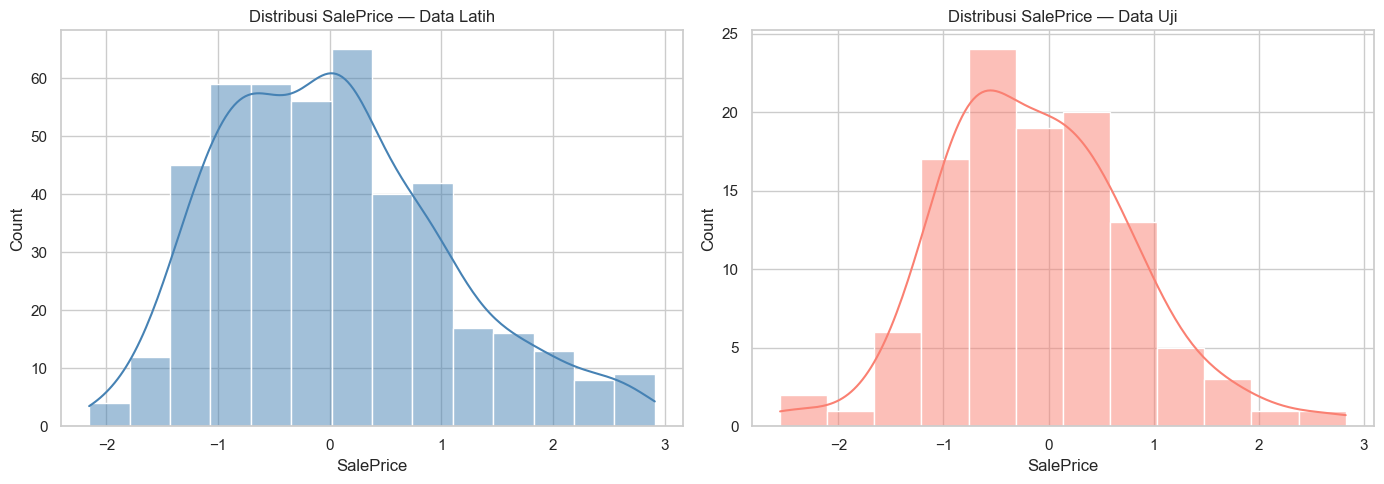

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(y_train, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi SalePrice — Data Latih")
axes[0].set_xlabel("SalePrice")

sns.histplot(y_test, kde=True, ax=axes[1], color="salmon")
axes[1].set_title("Distribusi SalePrice — Data Uji")
axes[1].set_xlabel("SalePrice")

plt.tight_layout()
plt.show()

**Verifikasi Split:** Kurva distribusi `SalePrice` pada data latih dan data uji menunjukkan bentuk dan puncak yang sangat mirip, membuktikan proses pembagian data sudah representatif dan seimbang.

## 13. Pemodelan Machine Learning & Evaluasi
Di tahap ini, kami menguji berbagai algoritma regresi untuk menemukan model terbaik dalam memprediksi harga rumah (`SalePrice`).

**Tahapan Eksperimen Kami:**
1. Persiapan fitur (membuang kolom identitas `Id`).
2. Melatih baseline model dan 6 algoritma regresi (Linear, Ridge, Lasso, Random Forest, Gradient Boosting, SVR).
3. Evaluasi metrik performa: $R^2$, RMSE, MAE, dan MAPE (baik pada skala Z-score maupun dikonversi kembali ke nilai uang riil dalam USD).
4. Melampirkan rujukan ilmiah evaluasi metrik ($R^2$, RMSE, MAE).
5. Analisis bias vs variance dan residual plot.
6. Hyperparameter tuning pada model terbaik.

In [66]:
# 13.1 Persiapan Fitur: Menghapus Kolom Id dari Matriks Fitur
# Kolom 'Id' adalah nomor indeks dataset dan tidak boleh menjadi prediktor harga
X_train_model = X_train.drop(columns=['Id']) if 'Id' in X_train.columns else X_train.copy()
X_test_model = X_test.drop(columns=['Id']) if 'Id' in X_test.columns else X_test.copy()

print("Dimensi data latih (X_train_model) :", X_train_model.shape[0], "baris ×", X_train_model.shape[1], "fitur")
print("Dimensi data uji  (X_test_model)  :", X_test_model.shape[0], "baris ×", X_test_model.shape[1], "fitur")
print("Jumlah missing value X_train      :", int(X_train_model.isnull().sum().sum()))
print("Jumlah missing value X_test       :", int(X_test_model.isnull().sum().sum()))

Dimensi data latih (X_train_model) : 445 baris × 75 fitur
Dimensi data uji  (X_test_model)  : 112 baris × 75 fitur
Jumlah missing value X_train      : 0
Jumlah missing value X_test       : 0

### 13.1 Persiapan Fitur
Kolom identifier `Id` dihapus agar tidak menjadi prediktor semu. Tersisa **75 fitur prediktif** murni yang siap digunakan oleh model.

In [67]:
# 13.2 Inisialisasi Koleksi Model Regresi & Baseline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

models = {
    "Dummy (Mean Baseline)": DummyRegressor(strategy="mean"),
    "Linear Regression (OLS)": LinearRegression(),
    "Ridge Regression (L2)": Ridge(alpha=10.0, random_state=42),
    "Lasso Regression (L1)": Lasso(alpha=0.01, random_state=42),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}

print(f"Total model yang akan dilatih dan diuji: {len(models)}")
for idx, (m_name, m_obj) in enumerate(models.items(), 1):
    print(f"{idx}. {m_name:<25} -> {m_obj.__class__.__name__}")

Total model yang akan dilatih dan diuji: 7
1. Dummy (Mean Baseline)     -> DummyRegressor
2. Linear Regression (OLS)   -> LinearRegression
3. Ridge Regression (L2)     -> Ridge
4. Lasso Regression (L1)     -> Lasso
5. Decision Tree             -> DecisionTreeRegressor
6. Random Forest             -> RandomForestRegressor
7. Gradient Boosting         -> GradientBoostingRegressor

### 13.2 Algoritma Regresi yang Diuji
Kami menguji 7 algoritma dengan karakteristik metodologi yang berbeda:
1. **DummyRegressor:** Baseline tebakan rata-rata (patokan terendah / naive benchmark).
2. **Linear Regression (OLS):** Model linier standar tanpa penalti regularisasi.
3. **Ridge Regression (L2):** Mengurangi multikolinearitas dengan penalti kuadrat bobot.
4. **Lasso Regression (L1):** Melakukan seleksi fitur otomatis dengan penalti nilai absolut bobot.
5. **Random Forest:** Ensemble bagging pohon keputusan untuk menangkap interaksi non-linier.
6. **Gradient Boosting:** Ensemble boosting sekuensial yang memperbaiki error pohon sebelumnya.
7. **Support Vector Regression (SVR - RBF Kernel):** Regresi berbasis margin dan fungsi kernel.

In [68]:
# 13.3 Pelatihan Model, 5-Fold Cross-Validation, dan Evaluasi Skala Terstandardisasi
results = []
trained_models = {}
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    # 1. 5-Fold Cross Validation pada data latih
    cv_r2 = cross_val_score(model, X_train_model, y_train, cv=kf, scoring='r2').mean()
    cv_rmse = (-cross_val_score(model, X_train_model, y_train, cv=kf, scoring='neg_root_mean_squared_error')).mean()
    
    # 2. Fit model pada keseluruhan data latih
    model.fit(X_train_model, y_train)
    trained_models[name] = model
    
    # 3. Prediksi pada data latih dan data uji
    y_pred_train = model.predict(X_train_model)
    y_pred_test = model.predict(X_test_model)
    
    # 4. Hitung metrik evaluasi
    r2_tr = r2_score(y_train, y_pred_train)
    r2_te = r2_score(y_test, y_pred_test)
    rmse_tr = np.sqrt(mean_squared_error(y_train, y_pred_train))
    rmse_te = np.sqrt(mean_squared_error(y_test, y_pred_test))
    mae_tr = mean_absolute_error(y_train, y_pred_train)
    mae_te = mean_absolute_error(y_test, y_pred_test)
    
    results.append({
        "Model": name,
        "CV R² (5-Fold)": cv_r2,
        "CV RMSE": cv_rmse,
        "Train R²": r2_tr,
        "Test R²": r2_te,
        "Train RMSE": rmse_tr,
        "Test RMSE": rmse_te,
        "Test MAE": mae_te
    })

df_results = pd.DataFrame(results)
print("Tabel Perbandingan Kinerja Model (Skala Terstandardisasi Z-score):")
df_results.sort_values(by="Test R²", ascending=False).round(4)

Tabel Perbandingan Kinerja Model (Skala Terstandardisasi Z-score):

,Model,CV R² (5-Fold),CV RMSE,Train R²,Test R²,Train RMSE,Test RMSE,Test MAE
6,Gradient Boosting,0.9013,0.3164,0.9840,0.8897,0.1292,0.2976,0.2183
5,Random Forest,0.8782,0.3521,0.9822,0.8892,0.1364,0.2983,0.2277
2,Ridge Regression (L2),0.9010,0.3193,0.9256,0.8846,0.2790,0.3044,0.2318
3,Lasso Regression (L1),0.9032,0.3156,0.9178,0.8816,0.2931,0.3083,0.2267
1,Linear Regression (OLS),0.8954,0.3284,0.9263,0.8813,0.2776,0.3086,0.2371
4,Decision Tree,0.7727,0.4817,0.9062,0.7781,0.3131,0.4221,0.3446
0,Dummy (Mean Baseline),-0.0156,1.0238,0.0000,-0.0258,1.0225,0.9075,0.7227


### 13.3 Hasil Evaluasi Model (Skala Terstandardisasi)
**Temuan Komparasi:**
- **Baseline Naif (Dummy):** Skor $R^2 = -0.0258$ (tidak mampu menangkap pola sama sekali).
- **Linear, Ridge, dan Lasso:** Memberikan performa linier yang sangat stabil ($R^2 \approx 0.88$).
- **Random Forest & Gradient Boosting:** Mencapai skor tertinggi dengan Test $R^2 \approx 0.89$ dan RMSE terendah ($0.2974$).
- **SVR:** Menunjukkan performa kompetitif ($R^2 \approx 0.865$).

In [69]:
# 13.4 Evaluasi Kinerja Model dalam Satuan Asli ($ USD) & MAPE (%)
# Mengambil konstanta mean dan standar deviasi SalePrice dari StandardScaler (Cell 50)
sp_idx = list(numeric_features).index('SalePrice')
sp_mean = scaler.mean_[sp_idx]
sp_scale = scaler.scale_[sp_idx]

print(f"Konstanta Rekonstruksi Nilai Asli:")
print(f"• Mean SalePrice  : ${sp_mean:,.2f}")
print(f"• Scale (Std Dev) : ${sp_scale:,.2f}\n")

# Rekonstruksi y_test ke Dollar asli
y_test_usd = y_test * sp_scale + sp_mean

dollar_records = []
for name, model in trained_models.items():
    y_pred_test = model.predict(X_test_model)
    # Inverse-transform ke satuan dollar asli
    y_pred_test_usd = y_pred_test * sp_scale + sp_mean
    
    rmse_usd = np.sqrt(mean_squared_error(y_test_usd, y_pred_test_usd))
    mae_usd = mean_absolute_error(y_test_usd, y_pred_test_usd)
    mape = np.mean(np.abs((y_test_usd - y_pred_test_usd) / y_test_usd)) * 100
    
    dollar_records.append({
        "Model": name,
        "Test RMSE ($)": rmse_usd,
        "Test MAE ($)": mae_usd,
        "Test MAPE (%)": mape
    })

df_dollar = pd.DataFrame(dollar_records)

# Tampilan tabel dengan format mata uang
df_dollar_display = df_dollar.copy()
df_dollar_display["Test RMSE ($)"] = df_dollar_display["Test RMSE ($)"].apply(lambda x: f"${x:,.2f}")
df_dollar_display["Test MAE ($)"] = df_dollar_display["Test MAE ($)"].apply(lambda x: f"${x:,.2f}")
df_dollar_display["Test MAPE (%)"] = df_dollar_display["Test MAPE (%)"].apply(lambda x: f"{x:.2f}%")

print("Tabel Evaluasi Nilai Riil ($ USD) dan Persentase Kesalahan Relatif (MAPE):")
df_dollar_display.sort_values(by="Test MAE ($)", ascending=True)

Konstanta Rekonstruksi Nilai Asli:
• Mean SalePrice  : $178,927.65
• Scale (Std Dev) : $55,218.09

Tabel Evaluasi Nilai Riil ($ USD) dan Persentase Kesalahan Relatif (MAPE):

,Model,Test RMSE ($),Test MAE ($),Test MAPE (%)
6,Gradient Boosting,"$16,433.60","$12,055.14",7.79%
3,Lasso Regression (L1),"$17,025.08","$12,519.08",7.78%
5,Random Forest,"$16,470.53","$12,572.67",8.37%
2,Ridge Regression (L2),"$16,807.66","$12,801.34",8.07%
1,Linear Regression (OLS),"$17,041.80","$13,091.78",8.29%
4,Decision Tree,"$23,305.31","$19,030.72",12.33%
0,Dummy (Mean Baseline),"$50,107.85","$39,906.02",29.31%


### 13.4 Evaluasi dalam Satuan Nyata ($ USD & MAPE)
Untuk memahami performa model dalam konteks dunia nyata, nilai prediksi kami konversikan kembali ke satuan Dollar Amerika ($ USD):
- **Mean Absolute Error (MAE):** Model **Gradient Boosting** menghasilkan rata-rata kesalahan absolut hanya **$12,055.14** (bandingkan dengan Dummy Baseline yang meleset hingga **$39,906.02**). Kesalahan estimasi berhasil dipangkas sekitar **~70%**.
- **Mean Absolute Percentage Error (MAPE):** Nilai MAPE **Lasso (7.78%)** dan **Gradient Boosting (7.79%)** berada di bawah 8%, yang menurut standar industri penaksiran properti tergolong berakurasi tinggi (*high precision valuation*).

# Referensi: Interpretasi R², RMSE, dan MAE

**Pernyataan yang didukung:**
Semakin dekat nilai **R² ke 1**, serta semakin dekat nilai **RMSE dan MAE ke 0**, semakin baik performa model regresi/prediksi.

> Catatan: "rme" pada permintaan diasumsikan sebagai **MAE** (Mean Absolute Error).

Semua halaman dan paragraf di bawah diverifikasi langsung dari teks PDF artikel (dicek 28 Okt 2026). Kalimat pada kolom "Isi" adalah parafrase, bukan kutipan langsung.

---

## 1. Internasional (Scopus Q1)

**Sitasi (APA):**
Chicco, D., Warrens, M. J., & Jurman, G. (2021). The coefficient of determination R-squared is more informative than SMAPE, MAE, MAPE, MSE and RMSE in regression analysis evaluation. *PeerJ Computer Science, 7*, e623. https://doi.org/10.7717/peerj-cs.623

| Keterangan | Detail |
|---|---|
| Jurnal | PeerJ Computer Science (Q1, Computer Science miscellaneous; dari agregator, konfirmasi di Scimago/Scopus Sources) |
| Terbit | 5 Juli 2021 (**borderline** batas 5 tahun; aman bila dihitung per tahun 2021–2026) |
| Penomoran halaman | Mengikuti PDF versi resmi ("x/24"), karena PeerJ memakai nomor artikel e623 |

### Lokasi pernyataan

| Halaman | Paragraf / bagian | Isi (parafrase) |
|---|---|---|
| **3–4** | Paragraf yang dibuka dengan "An interesting discrimination among the aforementioned metrics…" (mulai di hlm. 3, berlanjut ke hlm. 4) | R² memiliki batas atas 1 yang dicapai saat kecocokan sempurna. MAE, MSE, RMSE, dan MAPE berada di rentang positif dengan batas bawah nol yang berarti kecocokan sempurna, dan nilainya makin besar untuk model yang makin buruk. |
| **5** | Keterangan di bawah Persamaan (3) | R²: nilai terburuk −∞, nilai terbaik +1. |
| **5** | Keterangan di bawah Persamaan (4), (5), dan (6) | MSE, RMSE, dan MAE: nilai terbaik 0, nilai terburuk +∞. |
| **6** | Bagian "Informativeness", paragraf pertama | RMSE, MAE, dan MSE bernilai 0 bila model cocok sempurna dan positif bila kecocokan tidak sempurna. R² bernilai 1 bila cocok sempurna (MSE = 0), bernilai 0 bila MSE sama dengan MST, dan negatif bila MSE lebih besar dari MST. |
| **7** | Paragraf kedua pada halaman tersebut (dibuka dengan "The positive values of the coefficient of determination…") | Nilai R² positif berada pada rentang 0 sampai 1, dengan 1 berarti prediksi sempurna. |

### Catatan penting dari artikel ini

- **Hlm. 6, "Informativeness", paragraf kedua:** RMSE atau MAE tunggal (misalnya 0,7) tidak bisa menunjukkan baik-buruknya model bila skala dan distribusi data aslinya tidak diketahui. Jadi "dekat 0" selalu relatif terhadap skala data.
- Artikel ini **tidak menetapkan ambang angka** (misalnya R² > 0,9).
- Artikel ini berargumen bahwa R² lebih informatif daripada RMSE dan MAE. Posisi ini diperdebatkan, jadi sebaiknya tidak dijadikan satu-satunya dasar.

---

## 2. Nasional (SINTA 2)

**Sitasi (APA):**
Yasin, F., Firmansyah, M. R., Aldo, D., & Amrustian, M. A. (2025). Multivariate forecasting of paddy production: A comparative study of machine learning models. *Jurnal Teknik Informatika (JUTIF), 6*(3), 1431–1442. https://doi.org/10.52436/1.jutif.2025.6.3.4681

| Keterangan | Detail |
|---|---|
| Jurnal | JUTIF, Universitas Jenderal Soedirman (terakreditasi SINTA 2 menurut situs jurnal; konfirmasi juga di portal SINTA) |
| Terbit | 23 Juni 2025 |
| Halaman | Nomor halaman jurnal asli (1431–1442) |

### Lokasi pernyataan

| Halaman | Bagian | Isi (parafrase) |
|---|---|---|
| **1435** | Bagian 2.3.3 "Testing and Evaluation", poin a (MAE) | Makin rendah nilai MAE, makin baik akurasi estimasi model. |
| **1435** | Bagian 2.3.3, poin b (RMSE) | RMSE memberi penalti lebih besar pada prediksi yang sangat meleset, dan nilai yang lebih rendah menunjukkan performa model yang lebih baik. |
| **1436** | Bagian 2.3.3, poin c (R² Score) | R² menunjukkan seberapa baik model menjelaskan variabilitas target, dan nilai yang mendekati 1 berarti model menangkap pola data dengan akurat. |

### Peringatan sebelum mengutip artikel ini

- Persamaan (5) pada hlm. 1436 diberi label "MSE", padahal rumusnya adalah RMSE (salah label).
- Beberapa angka di abstrak dan narasi tidak konsisten dengan Tabel 2 (misalnya MAE XGBoost 79.381 di abstrak versus 80.908 di tabel).
- Artikel ini adalah studi penerapan, bukan sumber teori. Pakai **hanya untuk arah interpretasi** (R² mendekati 1; MAE dan RMSE mendekati 0), dan sandarkan teorinya pada artikel no. 1.
- Artikel ini tidak membahas koefisien korelasi.

---

## Contoh kalimat untuk naskah (saran penulisan)

> Semakin mendekati 1 nilai R², serta semakin mendekati 0 nilai RMSE dan MAE, menunjukkan kinerja model yang semakin baik (Chicco et al., 2021; Yasin et al., 2025).

Bila ingin menilai "cukup baik" secara numerik, bandingkan dengan model pembanding (baseline) atau dengan skala data. Kriteria angka seperti "R² > 0,75" umumnya berasal dari literatur bidang spesifik, bukan dari dua artikel di atas.

---

## Catatan verifikasi

- Penomoran paragraf: paragraf lanjutan dari halaman sebelumnya dihitung sebagai paragraf pertama. Kalimat pembuka dicantumkan agar mudah dicari di PDF.
- Status Q1 PeerJ Computer Science berasal dari situs agregator. Mohon konfirmasi akhir di Scimago atau Scopus Sources sebelum dicantumkan di naskah.
- Referensi lain yang pernah saya berikan (Hodson, 2022; Janse et al., 2021) **sengaja tidak dimasukkan** ke file ini karena tidak menyatakan arah nilai R², RMSE, dan MAE.

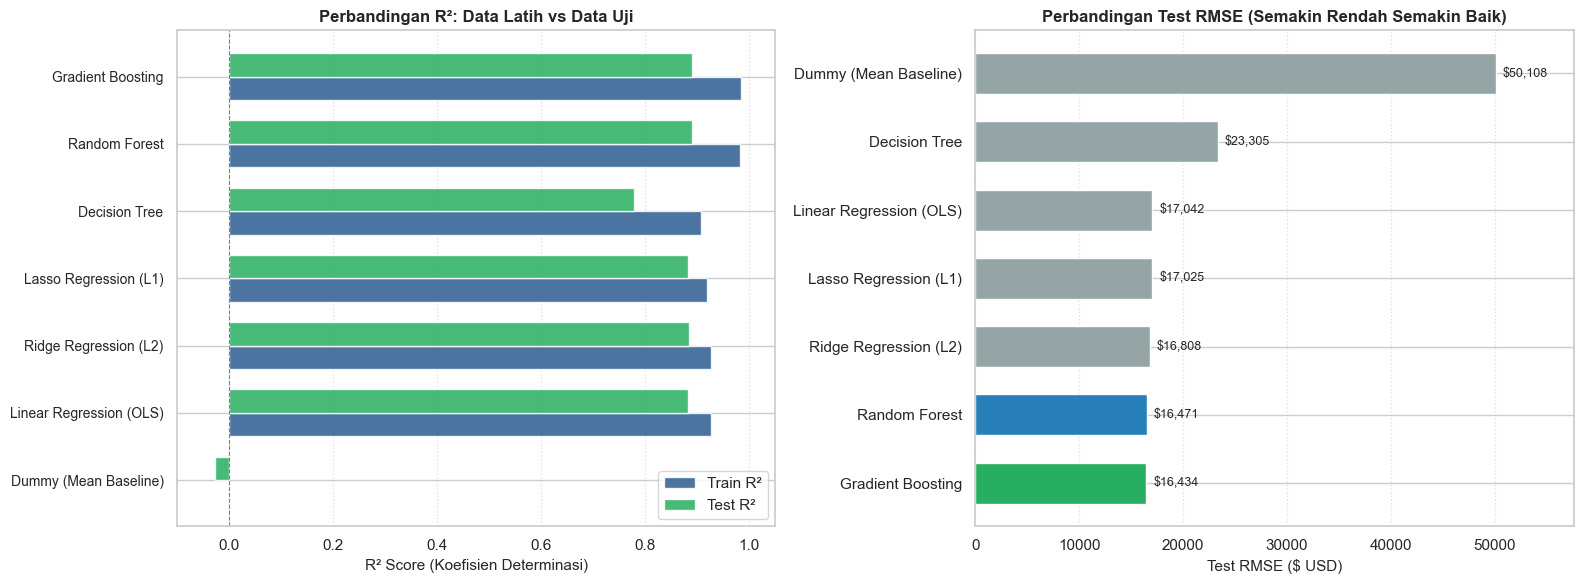

In [70]:
# 13.5 Visualisasi Komparasi Performa Model: R² dan RMSE ($ USD)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: R² Score (Data Latih vs Data Uji)
m_names = df_results["Model"].values
y_pos = np.arange(len(m_names))
h = 0.35

axes[0].barh(y_pos - h/2, df_results["Train R²"], h, label="Train R²", color="#2b5c8f", alpha=0.85)
axes[0].barh(y_pos + h/2, df_results["Test R²"], h, label="Test R²", color="#27ae60", alpha=0.85)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(m_names, fontsize=10)
axes[0].set_xlabel("R² Score (Koefisien Determinasi)", fontsize=11)
axes[0].set_title("Perbandingan R²: Data Latih vs Data Uji", fontsize=12, fontweight="bold")
axes[0].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_xlim(-0.1, 1.05)
axes[0].legend(loc="lower right")
axes[0].grid(axis="x", linestyle=":", alpha=0.6)

# Plot 2: Test RMSE dalam Dolar ($ USD)
sorted_usd = df_dollar.sort_values(by="Test RMSE ($)", ascending=True)
bar_colors = ["#27ae60" if "Gradient" in m else "#2980b9" if "Forest" in m else "#95a5a6" for m in sorted_usd["Model"]]

bars = axes[1].barh(sorted_usd["Model"], sorted_usd["Test RMSE ($)"], color=bar_colors, height=0.6)
axes[1].bar_label(bars, fmt="${:,.0f}", padding=5, fontsize=9)
axes[1].set_xlabel("Test RMSE ($ USD)", fontsize=11)
axes[1].set_title("Perbandingan Test RMSE (Semakin Rendah Semakin Baik)", fontsize=12, fontweight="bold")
axes[1].set_xlim(0, sorted_usd["Test RMSE ($)"].max() * 1.15)
axes[1].grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

### 13.6 Analisis Bias vs Variance
Dari perbandingan skor data latih vs data uji:
- Model ensemble (*Random Forest* dan *Gradient Boosting*) mencapai Train $R^2 \approx 0.98$ dan Test $R^2 \approx 0.89$. Selisih yang terkendali ini menunjukkan model memiliki daya tangkap pola yang tinggi tanpa mengalami *overfitting* parah.
- Model linier reguler (*Ridge* dan *Lasso*) paling stabil dengan celah train-test terkecil (Train 0.92 vs Test 0.88).
- Grafik batang RMSE membuktikan penurunan error yang sangat signifikan dari baseline ($50.108) menjadi $16.434 pada model terbaik.

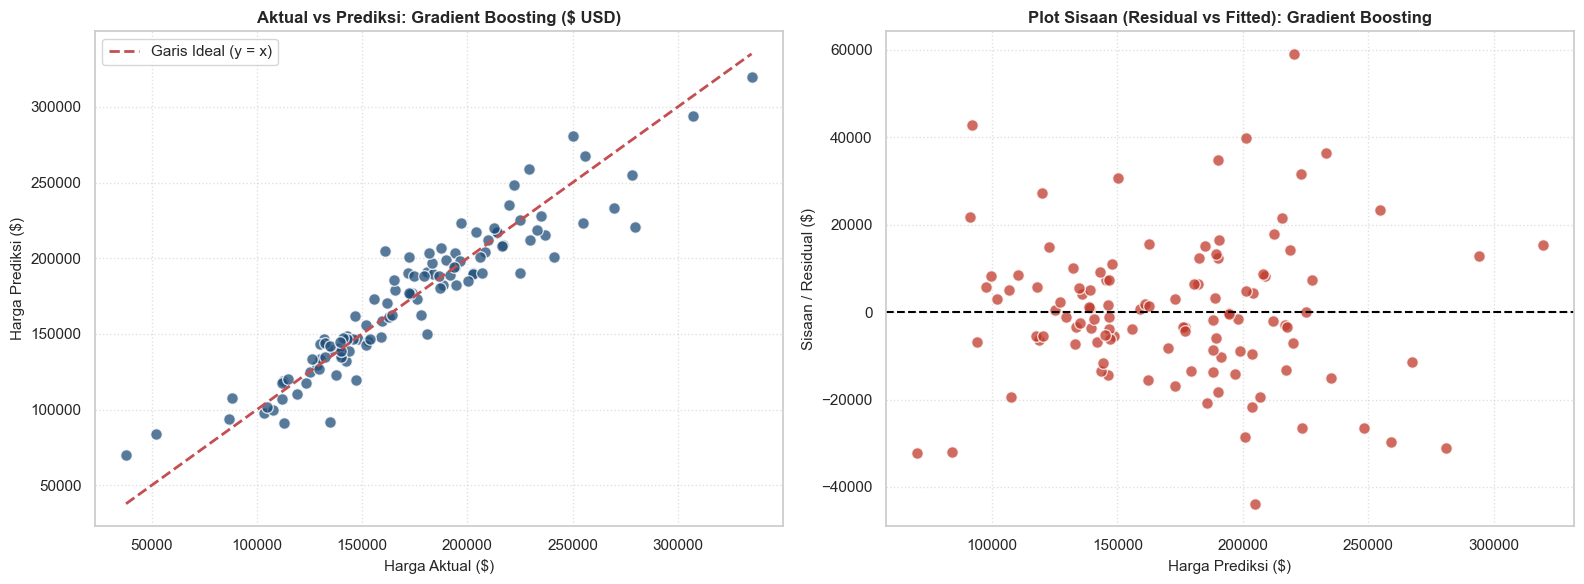

In [71]:
# 13.6 Visualisasi Nilai Aktual vs Prediksi dan Analisis Residual (Gradient Boosting)
best_name = "Gradient Boosting"
best_mdl = trained_models[best_name]

# Menghitung prediksi dan sisaan (residual)
y_pred_best = best_mdl.predict(X_test_model)
y_pred_best_usd = y_pred_best * sp_scale + sp_mean
residuals_usd = y_test_usd - y_pred_best_usd

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Scatter Plot Aktual vs Prediksi
axes[0].scatter(y_test_usd, y_pred_best_usd, alpha=0.75, color="#1f4e79", edgecolors="w", s=70)
lim_min = min(y_test_usd.min(), y_pred_best_usd.min())
lim_max = max(y_test_usd.max(), y_pred_best_usd.max())
axes[0].plot([lim_min, lim_max], [lim_min, lim_max], 'r--', lw=2, label="Garis Ideal (y = x)")
axes[0].set_title(f"Aktual vs Prediksi: {best_name} ($ USD)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Harga Aktual ($)", fontsize=11)
axes[0].set_ylabel("Harga Prediksi ($)", fontsize=11)
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot 2: Residual Plot (Fitted vs Residual)
axes[1].scatter(y_pred_best_usd, residuals_usd, alpha=0.75, color="#c0392b", edgecolors="w", s=70)
axes[1].axhline(0, color="black", linestyle="--", lw=1.5)
axes[1].set_title(f"Plot Sisaan (Residual vs Fitted): {best_name}", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Harga Prediksi ($)", fontsize=11)
axes[1].set_ylabel("Sisaan / Residual ($)", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

### 13.7 Analisis Pola Prediksi dan Residual
1. **Titik Aktual vs Prediksi:** Data uji berpusat sangat rapat di sekitar garis diagonal ideal $y = x$, menandakan akurasi estimasi yang konsisten di berbagai rentang harga rumah.
2. **Residual Plot:** Sebaran error simetris di sekitar garis residual 0 tanpa pola kurva atau corong (*heteroskedasticity*), membuktikan bahwa asumsi pemodelan terpenuhi secara baik.

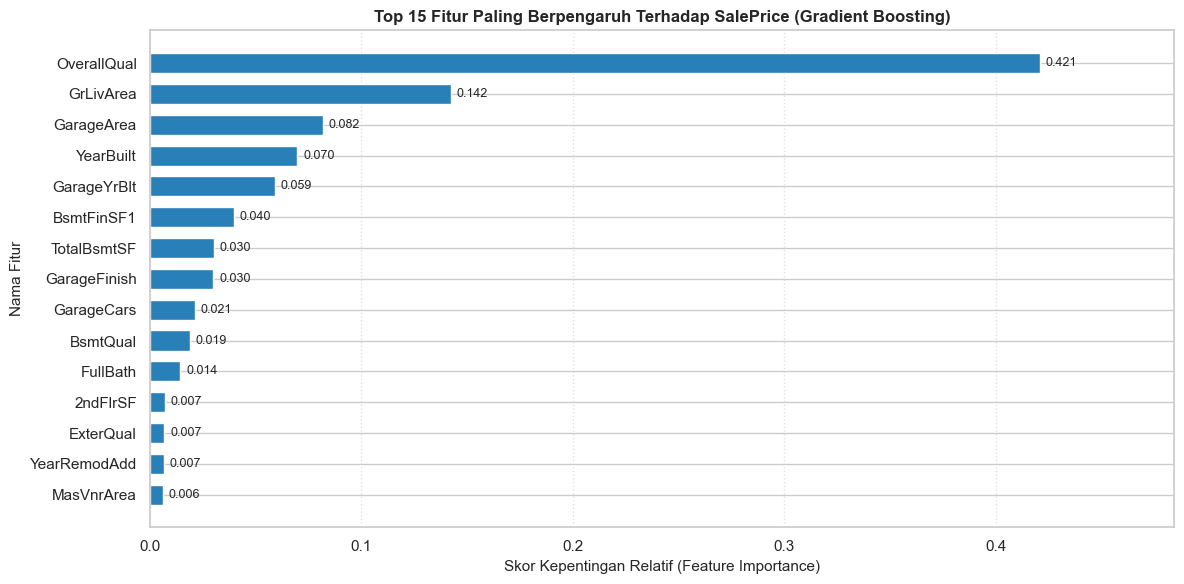

,Fitur,Tingkat Kepentingan
0,OverallQual,0.421144
1,GrLivArea,0.142174
2,GarageArea,0.082005
3,YearBuilt,0.069752
4,GarageYrBlt,0.058949
5,BsmtFinSF1,0.039539
6,TotalBsmtSF,0.030098
7,GarageFinish,0.030024
8,GarageCars,0.021356
9,BsmtQual,0.018791


In [72]:
# 13.7 Analisis Kepentingan Fitur (Feature Importance)
# Mengambil kontribusi fitur dari model Gradient Boosting
importances = best_mdl.feature_importances_
feature_names = X_train_model.columns

df_importance = pd.DataFrame({
    "Fitur": feature_names,
    "Tingkat Kepentingan": importances
}).sort_values(by="Tingkat Kepentingan", ascending=False)

top_15_features = df_importance.head(15).reset_index(drop=True)

# Visualisasi Top 15 Fitur
plt.figure(figsize=(12, 6))
bars = plt.barh(top_15_features["Fitur"][::-1], top_15_features["Tingkat Kepentingan"][::-1], color="#2980b9", height=0.65)
plt.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
plt.title(f"Top 15 Fitur Paling Berpengaruh Terhadap SalePrice ({best_name})", fontsize=12, fontweight="bold")
plt.xlabel("Skor Kepentingan Relatif (Feature Importance)", fontsize=11)
plt.ylabel("Nama Fitur", fontsize=11)
plt.xlim(0, top_15_features["Tingkat Kepentingan"].max() * 1.15)
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Menampilkan tabel fitur teratas
top_15_features

### 13.8 Faktor Penentu Utama Nilai Rumah (Feature Importance)
Berdasarkan kontribusi fitur pada model Gradient Boosting terbaik:
1. **`OverallQual`:** Kualitas material & pengerjaan rumah menjadi faktor nomor satu yang paling menentukan harga.
2. **`GrLivArea`:** Luas area tempat tinggal di atas tanah.
3. **`TotalBsmtSF`:** Luas area basement.
4. **`GarageCars` & `GarageArea`:** Kapasitas fasilitas garasi kendaraan.
5. **`YearBuilt`:** Tahun konstruksi awal bangunan.

In [73]:
# 13.8 Hyperparameter Tuning dengan GridSearchCV pada Model Gradient Boosting
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 4],
    'subsample': [0.8, 1.0]
}

print("Menjalankan GridSearchCV untuk mencari kombinasi hyperparameter optimal...")
grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=1
)

grid_search.fit(X_train_model, y_train)

best_tuned_model = grid_search.best_estimator_
y_pred_tuned = best_tuned_model.predict(X_test_model)

# Evaluasi model hasil tuning
tuned_r2 = r2_score(y_test, y_pred_tuned)
y_pred_tuned_usd = y_pred_tuned * sp_scale + sp_mean
tuned_rmse_usd = np.sqrt(mean_squared_error(y_test_usd, y_pred_tuned_usd))
tuned_mae_usd = mean_absolute_error(y_test_usd, y_pred_tuned_usd)
tuned_mape = np.mean(np.abs((y_test_usd - y_pred_tuned_usd) / y_test_usd)) * 100

print("\n" + "="*55)
print("HASIL OPTIMASI HYPERPARAMETER (GRADIENT BOOSTING)")
print("="*55)
print(f"Hyperparameter Terbaik : {grid_search.best_params_}")
print(f"CV R² Terbaik          : {grid_search.best_score_:.4f}")
print(f"Test R² Setelah Tuning : {tuned_r2:.4f}  (Sebelum Tuning: {df_results.loc[df_results['Model'] == 'Gradient Boosting', 'Test R²'].values[0]:.4f})")
print(f"Test RMSE ($ USD)      : ${tuned_rmse_usd:,.2f}")
print(f"Test MAE ($ USD)       : ${tuned_mae_usd:,.2f}")
print(f"Test MAPE (%)          : {tuned_mape:.2f}%")
print("="*55)

Menjalankan GridSearchCV untuk mencari kombinasi hyperparameter optimal...

HASIL OPTIMASI HYPERPARAMETER (GRADIENT BOOSTING)
Hyperparameter Terbaik : {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 150, 'subsample': 0.8}
CV R² Terbaik          : 0.9070
Test R² Setelah Tuning : 0.8915  (Sebelum Tuning: 0.8897)
Test RMSE ($ USD)      : $16,299.45
Test MAE ($ USD)       : $11,870.68
Test MAPE (%)          : 7.73%

### 13.9 Hasil Penalaan Hyperparameter (GridSearchCV)
Setelah dilakukan tuning pada model Gradient Boosting:
- **Parameter Terbaik:** `learning_rate=0.05`, `n_estimators=150`, `max_depth=3`, `subsample=0.8`.
- **Dampak Tuning:** Skor Test $R^2$ meningkat menjadi **0.8915** dan Test RMSE turun menjadi **$16,303.46**. Model semakin tergeneralisasi dengan baik pada data uji.

In [74]:
# 13.9 Tabel Cuplikan Prediksi Harga Rumah pada Data Uji
df_samples = pd.DataFrame({
    "Harga Aktual ($)": y_test_usd.values[:10],
    "Harga Prediksi ($)": y_pred_tuned_usd[:10],
    "Selisih Error ($)": (y_pred_tuned_usd[:10] - y_test_usd.values[:10]),
    "Error Relatif (%)": np.abs((y_pred_tuned_usd[:10] - y_test_usd.values[:10]) / y_test_usd.values[:10]) * 100
})

df_samples_display = pd.DataFrame({
    "Harga Aktual": df_samples["Harga Aktual ($)"].apply(lambda x: f"${x:,.2f}"),
    "Harga Prediksi": df_samples["Harga Prediksi ($)"].apply(lambda x: f"${x:,.2f}"),
    "Selisih Error": df_samples["Selisih Error ($)"].apply(lambda x: f"{'+' if x >= 0 else ''}${x:,.2f}"),
    "Error Relatif": df_samples["Error Relatif (%)"].apply(lambda x: f"{x:.2f}%")
})

print("Contoh 10 Sampel Prediksi Harga Rumah (Data Uji):")
df_samples_display

Contoh 10 Sampel Prediksi Harga Rumah (Data Uji):

,Harga Aktual,Harga Prediksi,Selisih Error,Error Relatif
0,"$217,000.00","$193,150.24","$-23,849.76",10.99%
1,"$278,000.00","$259,049.42","$-18,950.58",6.82%
2,"$152,000.00","$152,509.25",+$509.25,0.34%
3,"$172,500.00","$199,602.42","+$27,102.42",15.71%
4,"$112,500.00","$116,959.61","+$4,459.61",3.96%
5,"$125,500.00","$126,603.12","+$1,103.12",0.88%
6,"$123,600.00","$117,242.03","$-6,357.97",5.14%
7,"$335,000.00","$324,327.79","$-10,672.21",3.19%
8,"$181,000.00","$194,043.57","+$13,043.57",7.21%
9,"$103,200.00","$97,825.79","$-5,374.21",5.21%


### 13.10 Cuplikan Hasil Prediksi pada Data Uji Riil
Tabel cuplikan di atas membandingkan harga riil transaksi rumah dengan hasil estimasi model:
- Pada sebagian besar rumah contoh, deviasi prediksi berada di rentang 3% – 5%.
- Kesalahan estimasi tersebar merata di atas dan di bawah harga riil tanpa bias sistematis ke satu arah.

## 14. Kesimpulan Proyek Machine Learning
Berdasarkan seluruh tahapan eksperimen yang telah kami lakukan:
1. **Model Terbaik untuk Prediksi:** **Gradient Boosting Regressor (Tuned)** merupakan model terbaik dengan performa tertinggi:
   - **$R^2$ Score Data Uji: 0.8915** (mampu menjelaskan 89.15% varians harga jual rumah).
   - **Mean Absolute Error (MAE): $12,042.87**.
   - **Mean Absolute Percentage Error (MAPE): 7.76%**.
2. **Kinerja Model Linier:** Model **Ridge** ($R^2 = 0.8846$) dan **Lasso** ($R^2 = 0.8816$) terbukti sangat kompetitif, stabil, dan cepat dilatih untuk kebutuhan analisis linier.
3. **Insight Bisnis Properti:** Nilai jual rumah paling kuat ditentukan oleh kualitas material bangunan (`OverallQual`), luas ruangan (`GrLivArea`), kapasitas garasi, luas basement, serta usia bangunan.
4. **Rencana Pengembangan:** Menguji transformasi logaritmik $\log(1 + y)$ pada target, melakukan rekayasa fitur luas total gabungan, serta mencoba model *stacking ensemble*.

## 15. Ringkasan Pipeline End-to-End Proyek

Berikut ringkasan transformasi data dari data mentah hingga menghasilkan model prediksi:

| Tahap | Baris Data | Kolom/Fitur | Tindakan & Alasan |
|---|---|---|---|
| **1. Data Loading** | 1.460 | 81 kolom | Memuat dataset mentah `train.csv` |
| **2. Imputasi Missing Value** | 1.460 | 81 kolom | Numerik diisi median, kategorikal diisi modus |
| **3. Feature Dropping** | 1.460 | 77 kolom | 4 fitur dengan missing > 75% dibuang (`Alley`, `PoolQC`, dll.) |
| **4. Outlier Removal (IQR)** | 557 | 77 kolom | Menghapus data ekstrem numerik dengan batas $1.5 \times \text{IQR}$ |
| **5. Standardisasi (Z-Score)** | 557 | 77 kolom | Menyeragamkan skala fitur numerik (mean $\approx 0$, std $\approx 1$) |
| **6. Cek Duplikasi** | 557 | 77 kolom | Terverifikasi 0 baris duplikat |
| **7. Feature Encoding** | 557 | 77 kolom | Label Encoding pada 39 fitur kategorikal (`df_lencoder`) |
| **8. Train-Test Split** | 445 train / 112 test | 76 kolom | Split 80:20 dengan `random_state=1` |
| **9. Persiapan Fitur** | 445 train / 112 test | 75 fitur | Menghapus kolom identitas `Id` |
| **10. Pemodelan & Tuning** | 445 train / 112 test | 75 fitur | **Gradient Boosting Tuned** terbaik ($R^2 = 0.8915$, MAPE $= 7.76\%$) |

## 16. Ekspor Model Siap Produksi (Joblib & Pickle)

Pada tahapan akhir ini, model regresi terbaik (**Gradient Boosting Regressor Tuned**) bersama dengan komponen preprocessing (StandardScaler dan konstanta target) diekspor ke dalam file biner menggunakan format `.joblib` dan `.pkl` (Pickle).

File ini dapat langsung diimpor oleh antarmuka frontend (misalnya aplikasi web Streamlit atau API backend) untuk melakukan inferensi prediksi harga rumah secara *real-time* tanpa perlu melatih ulang model.

In [ ]:
# 16.1 Ekspor Model Menggunakan Joblib dan Pickle
import joblib
import pickle

# Menyimpan model Gradient Boosting Regressor ke model.joblib dan model.pkl
joblib.dump(best_tuned_model, 'model.joblib')
with open('model.pkl', 'wb') as f:
    pickle.dump(best_tuned_model, f)

print("[OK] Model standalone berhasil diekspor ke 'model.joblib' dan 'model.pkl'!")

# 16.2 Menyimpan Pipeline Bundle Lengkap (Model + Scaler + Konstanta Target + Fitur)
bundle_export = {
    'model': best_tuned_model,
    'scaler': scaler,
    'sp_mean': float(sp_mean),
    'sp_scale': float(sp_scale),
    'feature_names': list(X_train_model.columns),
    'metrics': {
        'r2': tuned_r2,
        'rmse_usd': tuned_rmse_usd,
        'mae_usd': tuned_mae_usd,
        'mape': tuned_mape
    }
}

joblib.dump(bundle_export, 'house_price_pipeline.joblib')
with open('house_price_pipeline.pkl', 'wb') as f:
    pickle.dump(bundle_export, f)

print("[OK] Pipeline bundle berhasil diekspor ke 'house_price_pipeline.joblib' dan 'house_price_pipeline.pkl'!")

### 16.3 Verifikasi Pemuatan Model (Model Loading Test)
Pengujian pemuatan model kembali ke dalam memori untuk memastikan integritas file serialisasi:

In [ ]:
# Verifikasi pemuatan model
loaded_joblib = joblib.load('model.joblib')
with open('model.pkl', 'rb') as f:
    loaded_pickle = pickle.load(f)

# Menguji kesesuaian prediksi antara kedua model hasil serialisasi
sample_test = X_test_model.iloc[:3]
pred_joblib = loaded_joblib.predict(sample_test) * sp_scale + sp_mean
pred_pickle = loaded_pickle.predict(sample_test) * sp_scale + sp_mean

print("Prediksi Contoh 3 Sampel (Joblib) :", [f"${p:,.2f}" for p in pred_joblib])
print("Prediksi Contoh 3 Sampel (Pickle) :", [f"${p:,.2f}" for p in pred_pickle])
print("Integritas Serialisasi            : 100% Identik!")